Task-specific Latent Representation Poisoning

1. class-wise poisoning by reversing IB: I(Z; Y)
2. sample-wise poisoning by reversing IB: I(Z; Z+delta)

In [1]:
import torch
import torchvision
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import numpy as np
from torch import Tensor
from typing import Callable, List, Optional, Type
import torch.nn.functional as F
import torchvision.datasets as datasets
from torch.utils.data import DataLoader


# transformation and dataloader
transform_ae = transforms.Compose([
    transforms.ToTensor()
])

transform_clf = transforms.Compose([
    transforms.ToTensor(),
    transforms.RandomHorizontalFlip(),
    transforms.RandomCrop(32, padding=4),
])

# dataset
train_dataset_ae = torchvision.datasets.CIFAR10(root='./data', train=True, download=True, transform=transform_ae)
train_dataset_clf = torchvision.datasets.CIFAR10(root='./data', train=True, download=True, transform=transform_clf)
test_dataset = torchvision.datasets.CIFAR10(root='./data', train=False, download=True, transform=transform_ae)

ae_dataloader = DataLoader(train_dataset_ae, batch_size=64, shuffle=True)
clf_dataloader = DataLoader(train_dataset_clf, batch_size=64, shuffle=True) # CK:clf_dataloader no need
test_dataloader = DataLoader(test_dataset, batch_size=64, shuffle=False)

100%|██████████| 170498071/170498071 [00:05<00:00, 30333616.46it/s]


Extracting ./data/cifar-10-python.tar.gz to ./data
Files already downloaded and verified
Files already downloaded and verified


In [2]:
def conv3x3(in_planes: int, out_planes: int, stride: int = 1, groups: int = 1, dilation: int = 1) -> nn.Conv2d:
    """3x3 convolution with padding"""
    return nn.Conv2d(
        in_planes,
        out_planes,
        kernel_size=3,
        stride=stride,
        padding=dilation,
        groups=groups,
        bias=False,
        dilation=dilation,
    )

def conv1x1(in_planes: int, out_planes: int, stride: int = 1) -> nn.Conv2d:
    """1x1 convolution"""
    return nn.Conv2d(in_planes, out_planes, kernel_size=1, stride=stride, bias=False)

def conv3x3Transposed(in_planes: int, out_planes: int, stride: int = 1, groups: int = 1, dilation: int = 1, output_padding: int = 0) -> nn.Conv2d:
    """3x3 convolution with padding"""
    return nn.ConvTranspose2d(
        in_planes,
        out_planes,
        kernel_size=3,
        stride=stride,
        padding=dilation,
        output_padding = output_padding, # output_padding is neccessary to invert conv2d with stride > 1
        groups=groups,
        bias=False,
        dilation=dilation,
    )

def conv1x1Transposed(in_planes: int, out_planes: int, stride: int = 1, output_padding: int = 0) -> nn.Conv2d:
    """1x1 convolution"""
    return nn.ConvTranspose2d(in_planes, out_planes, kernel_size=1, stride=stride, bias=False, output_padding = output_padding)


class LightBasicBlockDec(nn.Module):
    """The basic block architecture of resnet-18 network for smaller input images."""
    expansion: int = 1

    def __init__(
        self,
        inplanes: int,
        planes: int,
        stride: int = 1,
        output_padding: int = 0,
        upsample: Optional[nn.Module] = None,
        groups: int = 1,
        base_width: int = 64,
        dilation: int = 1,
        norm_layer: Optional[Callable[..., nn.Module]] = None,
    ) -> None:
        super().__init__()
        if norm_layer is None:
            norm_layer = nn.BatchNorm2d
        if groups != 1 or base_width != 64:
            raise ValueError("BasicBlock only supports groups=1 and base_width=64")
        if dilation > 1:
            raise NotImplementedError("Dilation > 1 not supported in BasicBlock")
        # Both self.conv1 and self.downsample layers downsample the input when stride != 1
        self.conv1 = conv3x3Transposed(planes, inplanes, stride, output_padding=output_padding)
        self.bn1 = norm_layer(inplanes)
        self.relu = nn.ReLU(inplace=True)
        self.conv2 = conv3x3Transposed(planes, planes)
        self.bn2 = norm_layer(planes)
        self.upsample = upsample
        self.stride = stride

    def forward(self, x: Tensor) -> Tensor:
        identity = x
        out = self.conv2(x)
        out = self.bn2(out)
        out = self.relu(out)

        out = self.conv1(out)
        out = self.bn1(out)

        if self.upsample is not None:
            identity = self.upsample(x)

        out += identity
        out = self.relu(out)
        return out



class LightDecoder(nn.Module):
    """The decoder model, following the architecture of resnet-18
    for smaller input images."""
    def __init__(
        self,
        block: Type[LightBasicBlockDec],
        layers: List[int],
        zero_init_residual: bool = False,
        groups: int = 1,
        width_per_group: int = 64,
        norm_layer: Optional[Callable[..., nn.Module]] = None
    ) -> None:
        super().__init__()
        if norm_layer is None:
            norm_layer = nn.BatchNorm2d
        self._norm_layer = norm_layer

        self.inplanes = 16 # It should be the shape of the output image CHANEL from the previous layer (layer1).
        self.dilation = 1
        self.groups = groups
        self.base_width = width_per_group
        self.de_conv1 = conv3x3Transposed(self.inplanes, 3)
        self.bn1 = norm_layer(64)
        self.relu = nn.ReLU(inplace=True)

        self.layer3 = self._make_layer(block, 64, layers[2], stride=2)
        self.layer2 = self._make_layer(block, 32, layers[1], stride=2)
        self.layer1 = self._make_layer(block, 16, layers[0], stride=1 ,output_padding = 0, last_block_dim=16) # stride = 2 output_padding = 1 NOTE: last_block_dim must be equal with the initila self.inplanes


        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")
            elif isinstance(m, (nn.BatchNorm2d, nn.GroupNorm)):
                nn.init.constant_(m.weight, 1)
                nn.init.constant_(m.bias, 0)

        # Zero-initialize the last BN in each residual branch,
        # so that the residual branch starts with zeros, and each residual block behaves like an identity.
        # This improves the model by 0.2~0.3% according to https://arxiv.org/abs/1706.02677
        if zero_init_residual:
            for m in self.modules():
                if isinstance(m, LightBasicBlockDec) and m.bn2.weight is not None:
                    nn.init.constant_(m.bn2.weight, 0)  # type: ignore[arg-type]

    def _make_layer(
        self,
        block: Type[LightBasicBlockDec],
        planes: int,
        blocks: int,
        stride: int = 2,
        output_padding: int = 1, # NOTE: output_padding will correct the dimensions of inverting conv2d with stride>1.
        # More info:https://pytorch.org/docs/stable/generated/torch.nn.ConvTranspose2d.html
        last_block_dim: int = 0,
    ) -> nn.Sequential:
        norm_layer = self._norm_layer
        upsample = None
        previous_dilation = self.dilation

        layers = []

        self.inplanes = planes * block.expansion

        for _ in range(1, blocks):
            layers.append(
                block(
                    self.inplanes,
                    planes,
                    groups=self.groups,
                    base_width=self.base_width,
                    dilation=self.dilation,
                    norm_layer=norm_layer,
                )
            )

        if last_block_dim == 0:
            last_block_dim = self.inplanes//2

        if stride != 1 or self.inplanes != planes * block.expansion:
            upsample = nn.Sequential(
                conv3x3Transposed(planes * block.expansion, last_block_dim, stride, output_padding=1),
                # conv1x1 will not work for this architecture since information about neighbor pixels will be missing
                # and cannot be reconstructed (there is no pooling layer). conv3x3 is an actual convolution layer where
                # info from neighbor pixels are included to the output pixel.
                norm_layer(last_block_dim),
            )

        layers.append( block(
                last_block_dim, planes, stride, output_padding, upsample, self.groups, self.base_width, previous_dilation, norm_layer
            ))
        return nn.Sequential(*layers)

    def _forward_impl(self, x: Tensor) -> Tensor:
        x = self.relu(x)
        x = self.bn1(x)
        x = self.layer3(x)
        x = self.layer2(x)
        x = self.layer1(x)

        x = self.de_conv1(x)
        return x


    def forward(self, x: Tensor) -> Tensor:
        return self._forward_impl(x)

In [3]:
class LightBasicBlockEnc(nn.Module):
    """The basic block architecture of resnet-18 network for smaller input images."""
    expansion: int = 1

    def __init__(
        self,
        inplanes: int,
        planes: int,
        stride: int = 1,
        downsample: Optional[nn.Module] = None,
        groups: int = 1,
        base_width: int = 64,
        dilation: int = 1,
        norm_layer: Optional[Callable[..., nn.Module]] = None,
    ) -> None:
        super().__init__()
        if norm_layer is None:
            norm_layer = nn.BatchNorm2d
        if groups != 1 or base_width != 64:
            raise ValueError("BasicBlock only supports groups=1 and base_width=64")
        if dilation > 1:
            raise NotImplementedError("Dilation > 1 not supported in BasicBlock")
        # Both self.conv1 and self.downsample layers downsample the input when stride != 1
        self.conv1 = conv3x3(inplanes, planes, stride)
        self.bn1 = norm_layer(planes)
        self.relu = nn.ReLU(inplace=True)
        self.conv2 = conv3x3(planes, planes)
        self.bn2 = norm_layer(planes)
        self.downsample = downsample

    def forward(self, x: Tensor) -> Tensor:
        identity = x
        out = self.conv1(x)
        out = self.bn1(out)
        out = self.relu(out)

        out = self.conv2(out)
        out = self.bn2(out)

        if self.downsample is not None:
            identity = self.downsample(x)

        out += identity
        out = self.relu(out)

        return out



class LightEncoder(nn.Module):
    """The encoder model, following the architecture of resnet-18
    for smaller input images."""
    def __init__(
        self,
        block: Type[LightBasicBlockEnc],
        layers: List[int],
        zero_init_residual: bool = False,
        groups: int = 1,
        width_per_group: int = 64,
        replace_stride_with_dilation: Optional[List[bool]] = None,
        norm_layer: Optional[Callable[..., nn.Module]] = None,
    ) -> None:
        super().__init__()
        if norm_layer is None:
            norm_layer = nn.BatchNorm2d
        self._norm_layer = norm_layer

        self.inplanes = 16 # 16
        self.dilation = 1
        if replace_stride_with_dilation is None:
            # each element in the tuple indicates if we should replace
            # the 2x2 stride with a dilated convolution instead
            replace_stride_with_dilation = [False, False, False]
        if len(replace_stride_with_dilation) != 3:
            raise ValueError(
                "replace_stride_with_dilation should be None "
                f"or a 3-element tuple, got {replace_stride_with_dilation}"
            )
        self.groups = groups
        self.base_width = width_per_group
        self.conv1 = conv3x3(3, self.inplanes)
        self.bn1 = norm_layer(self.inplanes)
        self.relu = nn.ReLU(inplace=True)
        self.layer1 = self._make_layer(block, 16, layers[0]) # stride=2
        self.layer2 = self._make_layer(block, 32, layers[1], stride=2, dilate=replace_stride_with_dilation[0])
        self.layer3 = self._make_layer(block, 64, layers[2], stride=2, dilate=replace_stride_with_dilation[1])

        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")
            elif isinstance(m, (nn.BatchNorm2d, nn.GroupNorm)):
                nn.init.constant_(m.weight, 1)
                nn.init.constant_(m.bias, 0)

        # Zero-initialize the last BN in each residual branch,
        # so that the residual branch starts with zeros, and each residual block behaves like an identity.
        # This improves the model by 0.2~0.3% according to https://arxiv.org/abs/1706.02677
        if zero_init_residual:
            for m in self.modules():
                if isinstance(m, LightBasicBlockEnc) and m.bn2.weight is not None:
                    nn.init.constant_(m.bn2.weight, 0)  # type: ignore[arg-type]

    def _make_layer(
        self,
        block: Type[LightBasicBlockEnc],
        planes: int,
        blocks: int,
        stride: int = 1,
        dilate: bool = False,
    ) -> nn.Sequential:
        norm_layer = self._norm_layer
        downsample = None
        previous_dilation = self.dilation
        if dilate:
            self.dilation *= stride
            stride = 1
        if stride != 1 or self.inplanes != planes * block.expansion:
            downsample = nn.Sequential(
                conv3x3(self.inplanes, planes * block.expansion, stride),
                # If we use conv1x1 here, then we should also use it in the decoder
                # part. But some pixels will be left unconstructed (simple noise) on decoding.
                norm_layer(planes * block.expansion),
            )

        layers = []
        layers.append(
            block(
                self.inplanes, planes, stride, downsample, self.groups, self.base_width, previous_dilation, norm_layer
            )
        )
        self.inplanes = planes * block.expansion
        for _ in range(1, blocks):
            layers.append(
                block(
                    self.inplanes,
                    planes,
                    groups=self.groups,
                    base_width=self.base_width,
                    dilation=self.dilation,
                    norm_layer=norm_layer,
                )
            )

        return nn.Sequential(*layers)

    def _forward_impl(self, x: Tensor) -> Tensor:
        x = self.conv1(x)
        x = self.bn1(x)
        x = self.relu(x)

        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)

        return x

    def forward(self, x: Tensor) -> Tensor:
        return self._forward_impl(x)

In [ ]:
class BasicBlockEnc(nn.Module):
    """The basic block architecture of resnet-18 network.
    """
    expansion: int = 1

    def __init__(
        self,
        inplanes: int,
        planes: int,
        stride: int = 1,
        downsample: Optional[nn.Module] = None,
        groups: int = 1,
        base_width: int = 64,
        dilation: int = 1,
        norm_layer: Optional[Callable[..., nn.Module]] = None,
    ) -> None:
        super().__init__()
        if norm_layer is None:
            norm_layer = nn.BatchNorm2d
        if groups != 1 or base_width != 64:
            raise ValueError("BasicBlock only supports groups=1 and base_width=64")
        if dilation > 1:
            raise NotImplementedError("Dilation > 1 not supported in BasicBlock")
        # Both self.conv1 and self.downsample layers downsample the input when stride != 1
        self.conv1 = conv3x3(inplanes, planes, stride)
        self.bn1 = norm_layer(planes)
        self.relu = nn.ReLU(inplace=True)
        self.conv2 = conv3x3(planes, planes)
        self.bn2 = norm_layer(planes)
        self.downsample = downsample
        self.stride = stride

    def forward(self, x: Tensor) -> Tensor:
        identity = x
        out = self.conv1(x)
        out = self.bn1(out)
        out = self.relu(out)

        out = self.conv2(out)
        out = self.bn2(out)

        if self.downsample is not None:
            identity = self.downsample(x)

        out += identity
        out = self.relu(out)

        return out



class Encoder(nn.Module):
    """The encoder model.
    """
    def __init__(
        self,
        block: Type[BasicBlockEnc],
        layers: List[int],
        zero_init_residual: bool = False,
        groups: int = 1,
        width_per_group: int = 64,
        replace_stride_with_dilation: Optional[List[bool]] = None,
        norm_layer: Optional[Callable[..., nn.Module]] = None,
    ) -> None:
        super().__init__()
        if norm_layer is None:
            norm_layer = nn.BatchNorm2d
        self._norm_layer = norm_layer

        self.inplanes = 64
        self.dilation = 1
        if replace_stride_with_dilation is None:
            # each element in the tuple indicates if we should replace
            # the 2x2 stride with a dilated convolution instead
            replace_stride_with_dilation = [False, False, False]
        if len(replace_stride_with_dilation) != 3:
            raise ValueError(
                "replace_stride_with_dilation should be None "
                f"or a 3-element tuple, got {replace_stride_with_dilation}"
            )
        self.groups = groups
        self.base_width = width_per_group
        self.conv1 = nn.Conv2d(3, self.inplanes, kernel_size=7, stride=2, padding=3, bias=False)
        self.bn1 = norm_layer(self.inplanes)
        self.relu = nn.ReLU(inplace=True)
        self.maxpool = nn.MaxPool2d(kernel_size=3, stride=2, padding=1)
        self.layer1 = self._make_layer(block, 64, layers[0])
        self.layer2 = self._make_layer(block, 128, layers[1], stride=2, dilate=replace_stride_with_dilation[0])
        self.layer3 = self._make_layer(block, 256, layers[2], stride=2, dilate=replace_stride_with_dilation[1])
        self.layer4 = self._make_layer(block, 512, layers[3], stride=2, dilate=replace_stride_with_dilation[2])

        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")
            elif isinstance(m, (nn.BatchNorm2d, nn.GroupNorm)):
                nn.init.constant_(m.weight, 1)
                nn.init.constant_(m.bias, 0)

        # Zero-initialize the last BN in each residual branch,
        # so that the residual branch starts with zeros, and each residual block behaves like an identity.
        # This improves the model by 0.2~0.3% according to https://arxiv.org/abs/1706.02677
        if zero_init_residual:
            for m in self.modules():
                if isinstance(m, BasicBlockEnc) and m.bn2.weight is not None:
                    nn.init.constant_(m.bn2.weight, 0)  # type: ignore[arg-type]

    def _make_layer(
        self,
        block: Type[BasicBlockEnc],
        planes: int,
        blocks: int,
        stride: int = 1,
        dilate: bool = False,
    ) -> nn.Sequential:
        norm_layer = self._norm_layer
        downsample = None
        previous_dilation = self.dilation
        if dilate:
            self.dilation *= stride
            stride = 1
        if stride != 1 or self.inplanes != planes * block.expansion:
            downsample = nn.Sequential(
                conv1x1(self.inplanes, planes * block.expansion, stride),
                norm_layer(planes * block.expansion),
            )

        layers = []
        layers.append(
            block(
                self.inplanes, planes, stride, downsample, self.groups, self.base_width, previous_dilation, norm_layer
            )
        )
        self.inplanes = planes * block.expansion
        for _ in range(1, blocks):
            layers.append(
                block(
                    self.inplanes,
                    planes,
                    groups=self.groups,
                    base_width=self.base_width,
                    dilation=self.dilation,
                    norm_layer=norm_layer,
                )
            )

        return nn.Sequential(*layers)

    def _forward_impl(self, x: Tensor) -> Tensor:
        x = self.conv1(x)
        x = self.bn1(x)
        x = self.relu(x)
        x = self.maxpool(x)

        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.layer4(x)

        return x

    def forward(self, x: Tensor) -> Tensor:
        return self._forward_impl(x)




In [ ]:
class BasicBlockDec(nn.Module):
    """The basic block architecture of resnet-18 network.
    """
    expansion: int = 1

    def __init__(
        self,
        inplanes: int,
        planes: int,
        stride: int = 1,
        output_padding: int = 0,
        upsample: Optional[nn.Module] = None,
        groups: int = 1,
        base_width: int = 64,
        dilation: int = 1,
        norm_layer: Optional[Callable[..., nn.Module]] = None,
    ) -> None:
        super().__init__()
        if norm_layer is None:
            norm_layer = nn.BatchNorm2d
        if groups != 1 or base_width != 64:
            raise ValueError("BasicBlock only supports groups=1 and base_width=64")
        if dilation > 1:
            raise NotImplementedError("Dilation > 1 not supported in BasicBlock")
        # Both self.conv1 and self.downsample layers downsample the input when stride != 1
        self.conv1 = conv3x3Transposed(planes, inplanes, stride, output_padding=output_padding)
        self.bn1 = norm_layer(inplanes)
        self.relu = nn.ReLU(inplace=True)
        self.conv2 = conv3x3Transposed(planes, planes)
        self.bn2 = norm_layer(planes)
        self.upsample = upsample
        self.stride = stride

    def forward(self, x: Tensor) -> Tensor:
        identity = x
        out = self.conv2(x)
        out = self.bn2(out)
        out = self.relu(out)

        out = self.conv1(out)
        out = self.bn1(out)

        if self.upsample is not None:
            identity = self.upsample(x)

        out += identity
        out = self.relu(out)
        return out





class Decoder(nn.Module):
    """The decoder model.
    """
    def __init__(
        self,
        block: Type[BasicBlockDec],
        layers: List[int],
        zero_init_residual: bool = False,
        groups: int = 1,
        width_per_group: int = 64,
        norm_layer: Optional[Callable[..., nn.Module]] = None
    ) -> None:
        super().__init__()
        if norm_layer is None:
            norm_layer = nn.BatchNorm2d
        self._norm_layer = norm_layer

        self.inplanes = 64 # change from 2048 to 64. It should be the shape of the output image chanel.
        self.dilation = 1
        self.groups = groups
        self.base_width = width_per_group
        self.de_conv1 = nn.ConvTranspose2d(self.inplanes, 3, kernel_size=7, stride=2, padding=3, bias=False, output_padding=1)
        self.bn1 = norm_layer(3)
        self.relu = nn.ReLU(inplace=True)
        self.unpool = nn.Upsample(scale_factor=2, mode='bilinear') # NOTE: invert max pooling

        self.layer4 = self._make_layer(block, 512, layers[3], stride=2)
        self.layer3 = self._make_layer(block, 256, layers[2], stride=2)
        self.layer2 = self._make_layer(block, 128, layers[1], stride=2)
        self.layer1 = self._make_layer(block, 64, layers[0], stride=1 ,output_padding = 0, last_block_dim=64)


        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")
            elif isinstance(m, (nn.BatchNorm2d, nn.GroupNorm)):
                nn.init.constant_(m.weight, 1)
                nn.init.constant_(m.bias, 0)

        # Zero-initialize the last BN in each residual branch,
        # so that the residual branch starts with zeros, and each residual block behaves like an identity.
        # This improves the model by 0.2~0.3% according to https://arxiv.org/abs/1706.02677
        if zero_init_residual:
            for m in self.modules():
                if isinstance(m, BasicBlockDec) and m.bn2.weight is not None:
                    nn.init.constant_(m.bn2.weight, 0)  # type: ignore[arg-type]

    def _make_layer(
        self,
        block: Type[BasicBlockDec],
        planes: int,
        blocks: int,
        stride: int = 2,
        output_padding: int = 1, # NOTE: output_padding will correct the dimensions of inverting conv2d with stride > 1.
        # More info:https://pytorch.org/docs/stable/generated/torch.nn.ConvTranspose2d.html
        last_block_dim: int = 0,
    ) -> nn.Sequential:
        norm_layer = self._norm_layer
        upsample = None
        previous_dilation = self.dilation

        layers = []

        self.inplanes = planes * block.expansion

        for _ in range(1, blocks):
            layers.append(
                block(
                    self.inplanes,
                    planes,
                    groups=self.groups,
                    base_width=self.base_width,
                    dilation=self.dilation,
                    norm_layer=norm_layer,
                )
            )

        if last_block_dim == 0:
            last_block_dim = self.inplanes//2

        if stride != 1 or self.inplanes != planes * block.expansion:
            upsample = nn.Sequential(
                conv1x1Transposed(planes * block.expansion, last_block_dim, stride, output_padding),
                norm_layer(last_block_dim),
            )

        layers.append( block(
                last_block_dim, planes, stride, output_padding, upsample, self.groups, self.base_width, previous_dilation, norm_layer
            ))
        return nn.Sequential(*layers)

    def _forward_impl(self, x: Tensor) -> Tensor:
        x = self.relu(x) # new
        x = self.layer4(x)
        x = self.layer3(x)
        x = self.layer2(x)
        x = self.layer1(x)

        x = self.unpool(x)
        x = self.de_conv1(x)
        x = self.bn1(x)
        # x = self.relu(x)
        return x


    def forward(self, x: Tensor) -> Tensor:
        return self._forward_impl(x)


In [4]:
class VAE(nn.Module):
    def __init__(self, network='light', num_layers=18, latent_dim=512, device='cuda', **kwargs):
        super().__init__()
        self.device = device
        self.network = network
        self.latent_dim = latent_dim
        self.sigmoid = nn.Sigmoid()
        self.activation = nn.ReLU(inplace=False)

        if self.network == 'default':
            if num_layers == 18:
                self.encoder = Encoder(BasicBlockEnc, [2, 2, 2, 2])
                self.decoder = Decoder(BasicBlockDec, [2, 2, 2, 2])
            elif num_layers == 34:
                self.encoder = Encoder(BasicBlockEnc, [3, 4, 6, 3])
                self.decoder = Decoder(BasicBlockDec, [3, 4, 6, 3])
            else:
                raise NotImplementedError("Only resnet 18 & 34 autoencoder have been implemented for images size >= 64x64.")
        elif self.network == 'light':
            if num_layers == 18:
                self.encoder = LightEncoder(LightBasicBlockEnc, [2, 2, 2])
                self.decoder = LightDecoder(LightBasicBlockDec, [2, 2, 2])
            elif num_layers == 20:
                self.encoder = LightEncoder(LightBasicBlockEnc, [3, 3, 3])
                self.decoder = LightDecoder(LightBasicBlockDec, [3, 3, 3])
            else:
                raise NotImplementedError("Only resnet 18 & 20 autoencoder have been implemented for images size < 64x64.")
        else:
            raise NotImplementedError("Only default and light resnet have been implemented. The light version corresponds to input datasets with size less than 64x64.")

        self.fc_mu = nn.Linear(4096, self.latent_dim)
        self.fc_var = nn.Linear(4096, self.latent_dim)
        self.fc_decoder = nn.Linear(self.latent_dim, 4096)
        self.mu_fc = nn.Linear(self.latent_dim, self.latent_dim)  # Additional FC layer for mu
        self.var_fc = nn.Linear(self.latent_dim, self.latent_dim)  # Additional FC layer for logvar

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        z = mu + eps * std
        # z = torch.clamp(z, min=0)
        return z

    def encode(self, x):
        conv_features = self.encoder(x)
        flatten_conv = torch.flatten(conv_features, start_dim=1)
        mu = self.fc_mu(flatten_conv)
        logvar = self.fc_var(flatten_conv)
        mu = self.activation(mu)
        logvar = self.activation(logvar)
        mu = self.mu_fc(mu)  # Additional FC layer for mu
        logvar = self.var_fc(logvar)  # Additional FC layer for logvar
        return mu, logvar

    def decode(self, z):
        z_decoded = self.fc_decoder(z)
        z_decoded = z_decoded.view(-1, 64, 8, 8)  # Adjust dimensions according to your decoder
        x_recon = self.decoder(z_decoded)
        return self.sigmoid(x_recon)

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        x_recon = self.decode(z)
        return x_recon, mu, logvar




In [5]:
class SimpleClassifier(nn.Module):
    def __init__(self, input_channels, num_classes):
        super(SimpleClassifier, self).__init__()
        self.fc = nn.Linear(input_channels, num_classes)

    def forward(self, x):
        x = self.fc(x)
        return x

class SimpleMLPClassifier(nn.Module):
    def __init__(self, input_channels, num_classes):
        super(SimpleMLPClassifier, self).__init__()
        self.fc1 = nn.Linear(input_channels, 128)
        self.fc2 = nn.Linear(128, num_classes)

    def forward(self, x):
        x = F.relu(self.fc1(x))
        x = self.fc2(x)
        return x

In [6]:
def vae_loss(recon_x, x, mu, logvar):
    recon_x = torch.clamp(recon_x, 0, 1)
    BCE = F.binary_cross_entropy(recon_x, x, reduction='mean')
    MSE = F.mse_loss(recon_x, x, reduction='mean')
    KLD = -0.5 * torch.mean(1 + logvar - mu.pow(2) - logvar.exp())
    return MSE + 0.001 * KLD # 0.001

# Define the training function
def train_vae_classifier(vae, classifier, ae_dataloader, test_dataloader, num_epochs=10):
    criterion_ae = vae_loss
    criterion_clf = nn.CrossEntropyLoss()

    optimizer = optim.AdamW(list(vae.parameters()) + list(classifier.parameters()), lr=5e-4) # 5e-4
    # scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.1, patience=3, verbose=True)


    for epoch in range(num_epochs):
        vae.train()
        classifier.train()

        running_loss_ae = 0.0
        running_loss_clf = 0.0

        for data in ae_dataloader:
            inputs, labels = data
            inputs = inputs.to(device)
            labels = labels.to(device)

            # forward
            optimizer.zero_grad()

            # VAE forward
            recon_x, mu, logvar = vae(inputs)
            # recon_x = torch.clamp(recon_x, 0, 1)
            if recon_x.shape != inputs.shape:
                print(f"Shape mismatch: recon_x {recon_x.shape}, inputs {inputs.shape}")
            loss_ae = criterion_ae(recon_x, inputs, mu, logvar)
            # Classifier forward
            z = vae.reparameterize(mu, logvar)
            outputs_clf = classifier(z)
            loss_clf = criterion_clf(outputs_clf, labels)

            # joint loss
            loss = loss_ae +  0.2 * loss_clf

            # backprop
            loss.backward()
            optimizer.step()

            running_loss_ae += loss_ae.item()
            running_loss_clf += loss_clf.item()

        # scheduler.step(loss)

        print(f'Epoch [{epoch+1}/{num_epochs}], Loss AE: {running_loss_ae/len(ae_dataloader)}, Loss Clf: {running_loss_clf/len(ae_dataloader)}')

        # Classifier evaluation
        classifier.eval()
        correct = 0
        total = 0
        with torch.no_grad():
            for data in test_dataloader:
                inputs, labels = data
                inputs, labels = inputs.to(device), labels.to(device)
                _, mu, logvar = vae(inputs)
                z = vae.reparameterize(mu, logvar)
                outputs = classifier(z)
                _, predicted = torch.max(outputs.data, 1)
                total += labels.size(0)
                correct += (predicted == labels).sum().item()

        print(f'Test Accuracy: {100 * correct / total}%')

        visualize_vae_outputs(vae, ae_dataloader, epoch)

def visualize_vae_outputs(vae, dataloader, epoch, num_images=5):
    vae.eval()
    dataiter = iter(dataloader)
    images, _ = next(dataiter)
    images = images.to(device)
    outputs, _, _ = vae(images)
    outputs = outputs.cpu().data
    # outputs = torch.clamp(outputs, 0, 1)

    fig, axes = plt.subplots(2, num_images, figsize=(12, 4))
    for i in range(num_images):
        ax = axes[0, i]
        ax.imshow(images[i].cpu().numpy().transpose(1, 2, 0))
        ax.axis('off')
        ax = axes[1, i]
        ax.imshow(outputs[i].numpy().transpose(1, 2, 0))
        ax.axis('off')

    plt.suptitle(f'Epoch {epoch + 1}')
    plt.show()


Epoch [1/15], Loss AE: 0.04002707831494872, Loss Clf: 1.4202434644674706
Test Accuracy: 58.19%


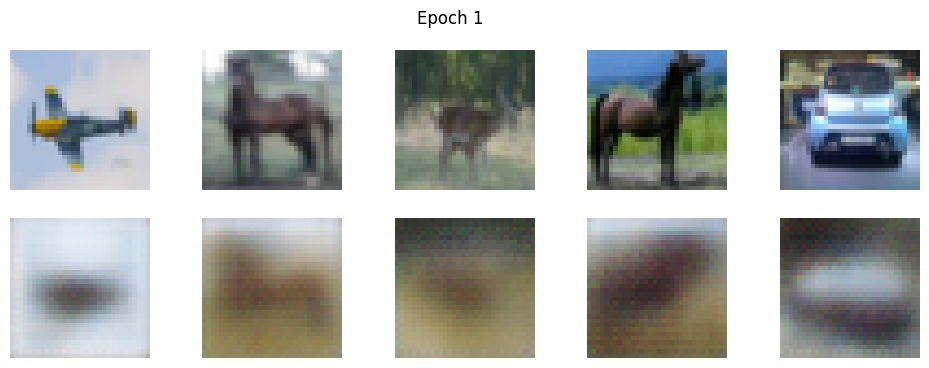

Epoch [2/15], Loss AE: 0.029810310896400294, Loss Clf: 0.9784599098250689
Test Accuracy: 68.46%


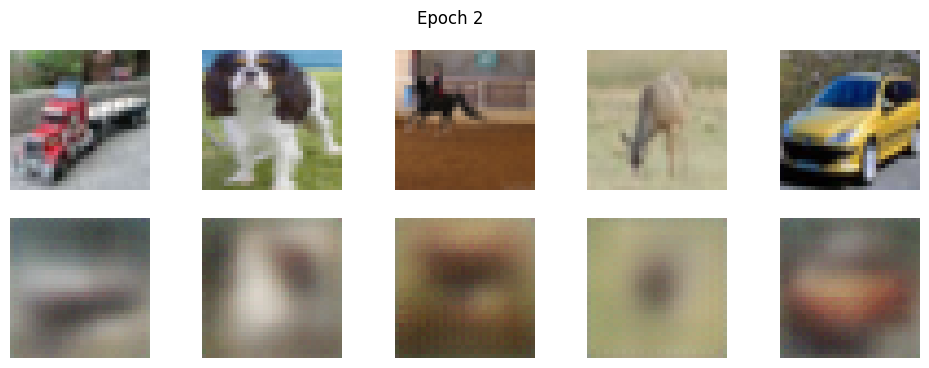

Epoch [3/15], Loss AE: 0.027858959272732516, Loss Clf: 0.7810954009099385
Test Accuracy: 68.67%


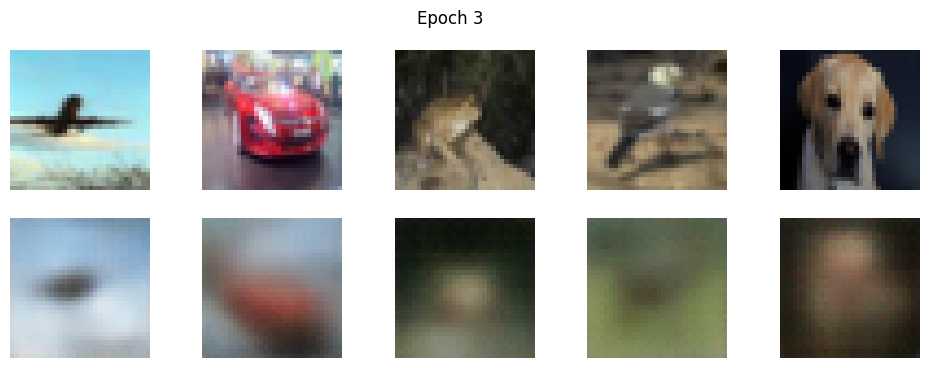

Epoch [4/15], Loss AE: 0.026540570708987354, Loss Clf: 0.6394584984959238
Test Accuracy: 71.24%


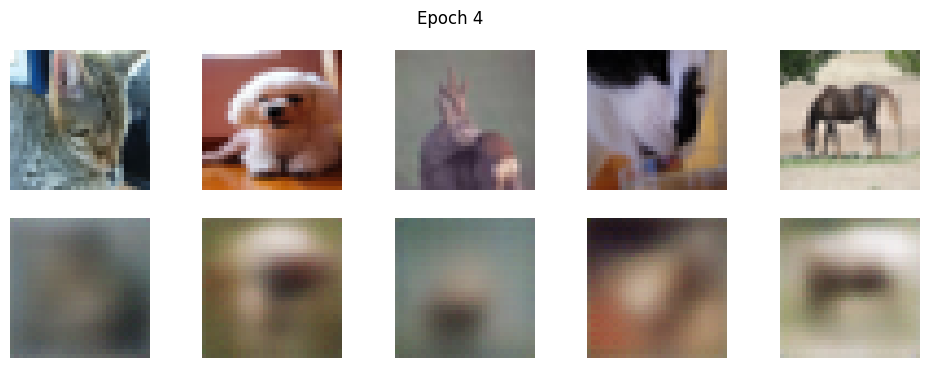

Epoch [5/15], Loss AE: 0.026194388873379708, Loss Clf: 0.5195990718539109
Test Accuracy: 72.6%


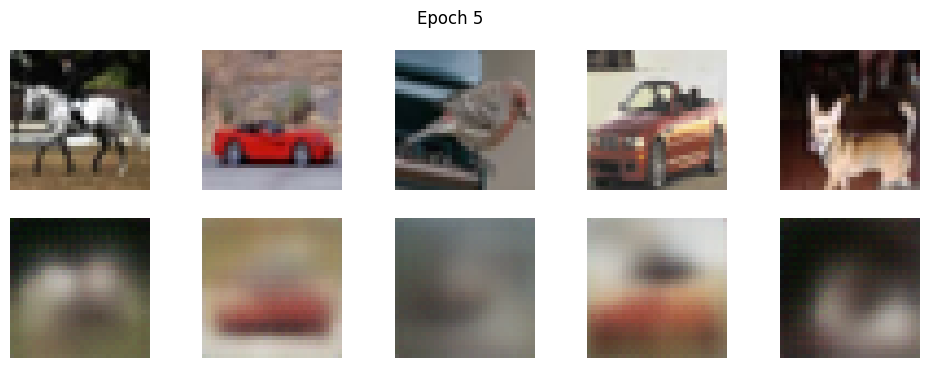

Epoch [6/15], Loss AE: 0.02599683364191095, Loss Clf: 0.4219200218577519
Test Accuracy: 72.74%


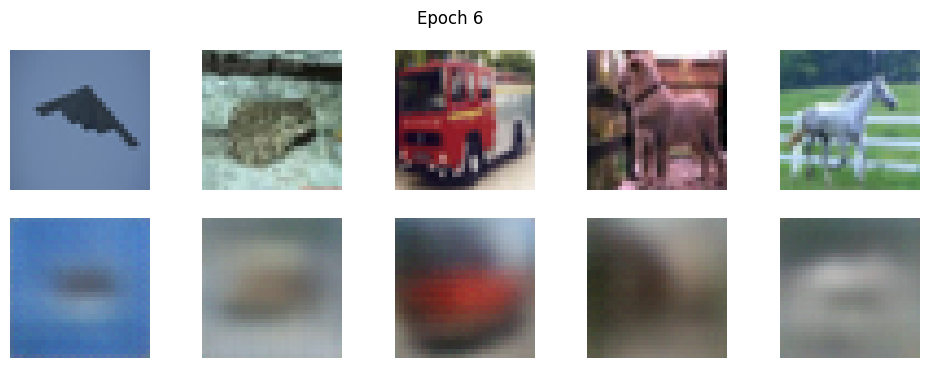

Epoch [7/15], Loss AE: 0.0259582375788399, Loss Clf: 0.34260348383041905
Test Accuracy: 73.22%


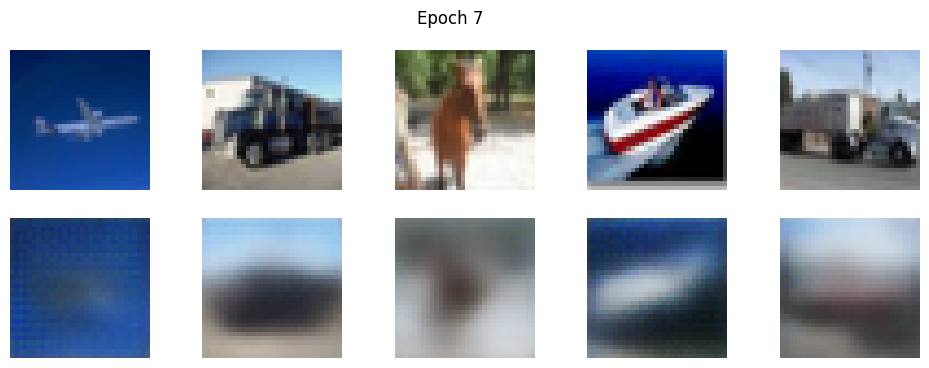

Epoch [8/15], Loss AE: 0.025735112512126908, Loss Clf: 0.26867550483826175
Test Accuracy: 73.53%


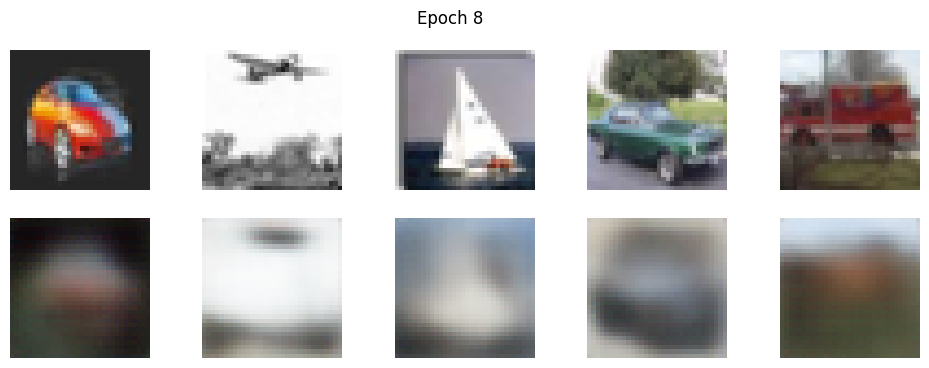

Epoch [9/15], Loss AE: 0.025809409215932003, Loss Clf: 0.22203603220146026
Test Accuracy: 74.02%


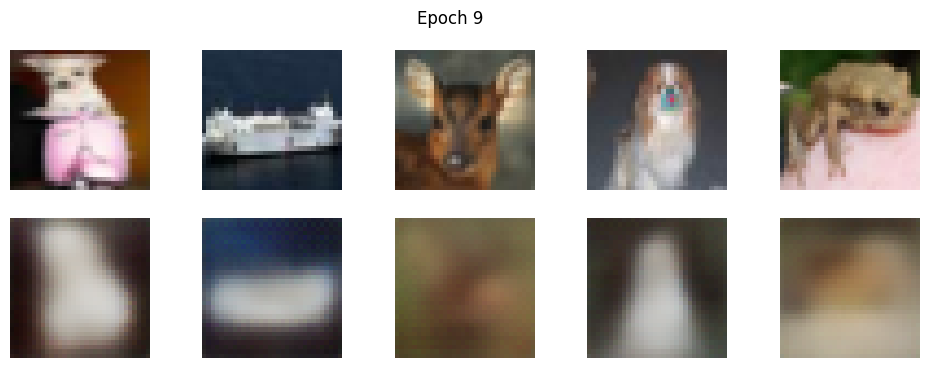

Epoch [10/15], Loss AE: 0.02561984037327797, Loss Clf: 0.18279177840332242
Test Accuracy: 73.05%


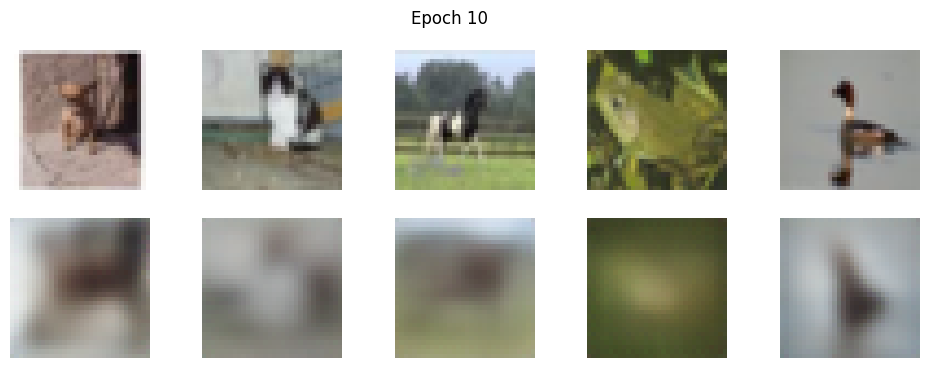

Epoch [11/15], Loss AE: 0.025472107326702388, Loss Clf: 0.15603825697899246
Test Accuracy: 73.7%


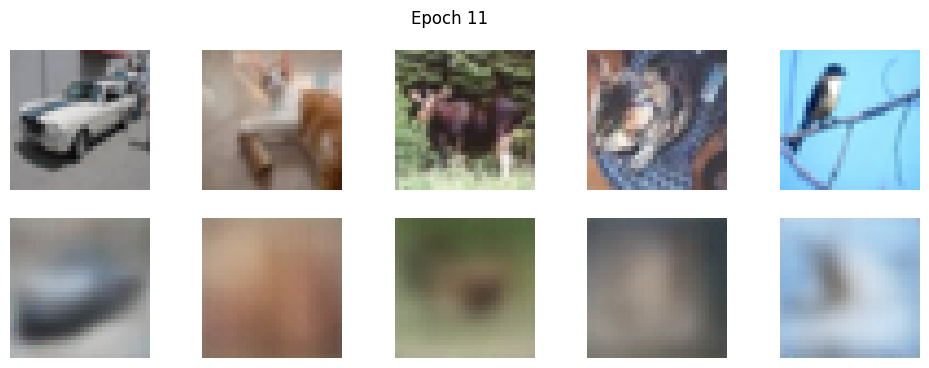

Epoch [12/15], Loss AE: 0.025072171552883236, Loss Clf: 0.13371230412603302
Test Accuracy: 74.32%


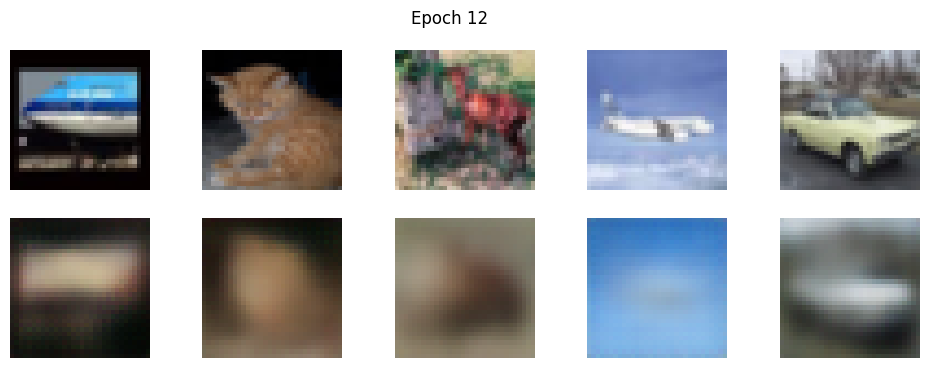

Epoch [13/15], Loss AE: 0.025054241623491277, Loss Clf: 0.12547604423171133
Test Accuracy: 74.47%


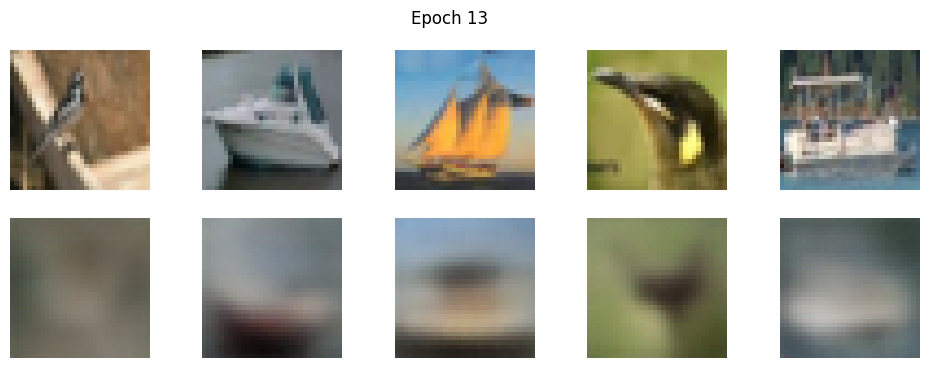

Epoch [14/15], Loss AE: 0.02488336587786827, Loss Clf: 0.11531642974351945
Test Accuracy: 73.43%


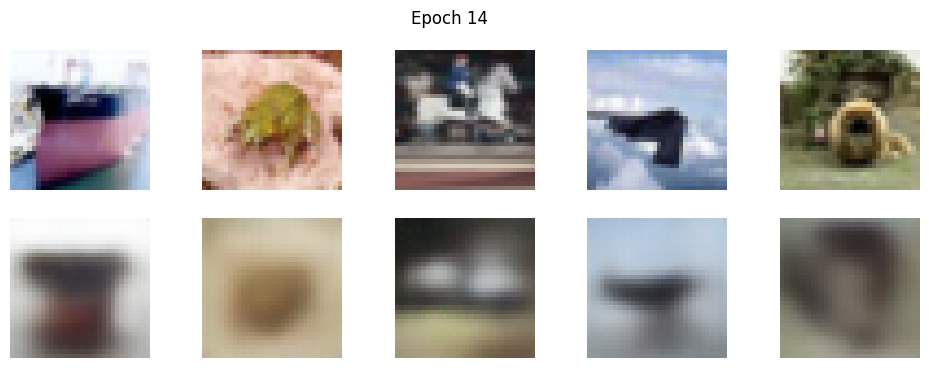

Epoch [15/15], Loss AE: 0.024738894392024067, Loss Clf: 0.10929750578473214
Test Accuracy: 74.05%


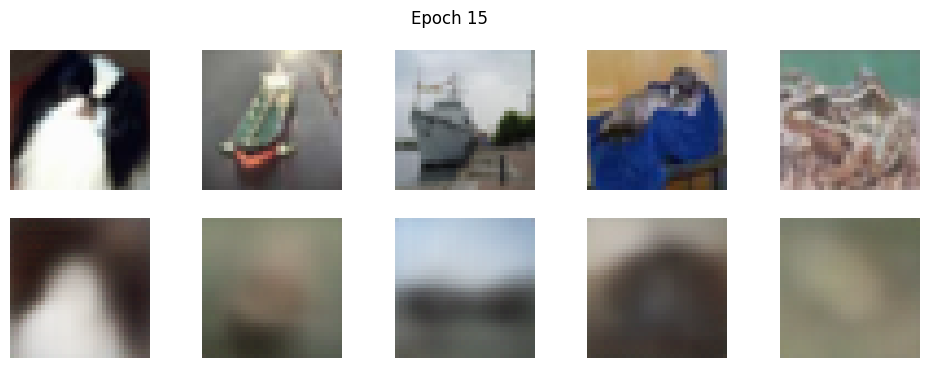

In [7]:
# Initialize model for VAE
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
vae = VAE(network='light', num_layers=18, latent_dim=512, device=device).to(device)
classifier = SimpleClassifier(input_channels=512, num_classes=10).to(device) # SimpleClassifier

train_vae_classifier(vae, classifier, ae_dataloader, test_dataloader, num_epochs=15)

5e-4, MSE 0.001*KLD is feasible

In [8]:
class LightEncoderWithSigmoid(nn.Module):
    """The encoder model with Sigmoid activation at the output."""
    def __init__(
        self,
        block: Type[LightBasicBlockEnc],
        layers: List[int],
        zero_init_residual: bool = False,
        groups: int = 1,
        width_per_group: int = 64,
        replace_stride_with_dilation: Optional[List[bool]] = None,
        norm_layer: Optional[Callable[..., nn.Module]] = None,
    ) -> None:
        super().__init__()
        if norm_layer is None:
            norm_layer = nn.BatchNorm2d
        self._norm_layer = norm_layer

        self.inplanes = 16  # Adjust according to light model
        self.dilation = 1
        if replace_stride_with_dilation is None:
            replace_stride_with_dilation = [False, False, False]
        if len(replace_stride_with_dilation) != 3:
            raise ValueError(
                "replace_stride_with_dilation should be None "
                f"or a 3-element tuple, got {replace_stride_with_dilation}"
            )
        self.groups = groups
        self.base_width = width_per_group
        self.conv1 = conv3x3(3, self.inplanes)  # Change initial conv layer
        self.bn1 = norm_layer(self.inplanes)
        self.relu = nn.ReLU(inplace=True)
        self.layer1 = self._make_layer(block, 16, layers[0])
        self.layer2 = self._make_layer(block, 32, layers[1], stride=2, dilate=replace_stride_with_dilation[0])
        self.layer3 = self._make_layer(block, 64, layers[2], stride=2, dilate=replace_stride_with_dilation[1])
        self.tanh = nn.Tanh()

        self.fc = nn.Linear(4096, 512)  # Additional mapping to match VAE latent dimension

        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")
            elif isinstance(m, (nn.BatchNorm2d, nn.GroupNorm)):
                nn.init.constant_(m.weight, 1)
                nn.init.constant_(m.bias, 0)
        if zero_init_residual:
            for m in self.modules():
                if isinstance(m, LightBasicBlockEnc) and m.bn2.weight is not None:
                    nn.init.constant_(m.bn2.weight, 0)

    def _make_layer(
        self,
        block: Type[LightBasicBlockEnc],
        planes: int,
        blocks: int,
        stride: int = 1,
        dilate: bool = False,
    ) -> nn.Sequential:
        norm_layer = self._norm_layer
        downsample = None
        previous_dilation = self.dilation
        if dilate:
            self.dilation *= stride
            stride = 1
        if stride != 1 or self.inplanes != planes * block.expansion:
            downsample = nn.Sequential(
                conv1x1(self.inplanes, planes * block.expansion, stride),
                norm_layer(planes * block.expansion),
            )
        layers = []
        layers.append(
            block(
                self.inplanes, planes, stride, downsample, self.groups, self.base_width, previous_dilation, norm_layer
            )
        )
        self.inplanes = planes * block.expansion
        for _ in range(1, blocks):
            layers.append(
                block(
                    self.inplanes,
                    planes,
                    groups=self.groups,
                    base_width=self.base_width,
                    dilation=self.dilation,
                    norm_layer=norm_layer,
                )
            )
        return nn.Sequential(*layers)

    def forward(self, x: Tensor) -> Tensor:
        x = self.conv1(x)
        x = self.bn1(x)
        x = self.relu(x)
        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = torch.flatten(x, 1)
        x = self.fc(x)  # Add mapping to 512
        x = F.normalize(x, p=2, dim=1)  # Normalize the output on the L-2 ball
        ######### Implement L-infinity (max norm) normalization  HRIIRBLE OUTPUT !!!
        ######### max_vals, _ = x.max(dim=1, keepdim=True)
        ######### x =  x / max_vals
        return x
        ###
        ### we only use sigmoid to nearly guarantee l_inf norm ###
        ###
        # x = 0.2 * F.normalize(x, p=2, dim=1)  # Normalize the output on the L-2 ball
        # Implement L-infinity (max norm) normalization
        # max_vals, _ = x.max(dim=1, keepdim=True)
        # x =  0.05 * x / max_vals
        # return x

        ##### it is a bad idea x = self.tanh(x)


In [9]:
def PTB(z, encoded_new, epsilon=.75, norm_type='l2'):
    """
    Perform operations on z and encoded_new as described.

    Parameters:
    - z: Tensor of shape (batch, channel)
    - encoded_new: Tensor of shape (batch, channel)
    - epsilon: Small value to avoid division by zero (default: 1e-8)
    - norm_type: Type of norm to use ('l2' or 'inf')

    Returns:
    - PTB: Tensor after processing encoded_new
    - combined: Tensor after processing z and encoded_new
    """
    if isinstance(z, np.ndarray):
        # Using NumPy
        if norm_type == 'l2':
            # Calculate the L2 norm of each row in z
            l2_norm_z = np.linalg.norm(z, axis=1, keepdims=True)

            # Scale encoded_new by L2 norm of z
            scaled_encoded_new = encoded_new * epsilon * l2_norm_z

            combined = z + scaled_encoded_new

        elif norm_type == 'inf':
            # Calculate the inf norm (max norm) of each row in z
            max_vals_z = np.max(np.abs(z), axis=1, keepdims=True)

            # Scale encoded_new by inf norm of z
            scaled_encoded_new = encoded_new * epsilon * max_vals_z

            combined = z + scaled_encoded_new
        elif norm_type == 'l2_in':
            # Calculate the L2 norms of z and encoded_new
            l2_norm_z = np.linalg.norm(z, axis=1, keepdims=True)
            l2_norm_encoded_new = np.linalg.norm(encoded_new, axis=1, keepdims=True)

            # Calculate the scaling factor
            scaling_factor = np.minimum(1, epsilon * l2_norm_z / l2_norm_encoded_new)


            # Scale encoded_new to ensure the ratio is within epsilon
            scaled_encoded_new = encoded_new * scaling_factor

            combined = z + scaled_encoded_new
        else:
            raise ValueError("Unsupported norm type. Use 'l2' or 'inf'.")

    elif torch.is_tensor(z):
        # Using PyTorch
        if norm_type == 'l2':
            # Calculate the L2 norm of each row in z
            l2_norm_z = torch.norm(z, p=2, dim=1, keepdim=True)

            # Scale encoded_new by L2 norm of z
            scaled_encoded_new = encoded_new * epsilon * l2_norm_z

            combined = z + scaled_encoded_new

        elif norm_type == 'inf':
            # Calculate the inf norm (max norm) of each row in z
            max_vals_z, _ = z.abs().max(dim=1, keepdim=True)

            # Scale encoded_new by inf norm of z
            scaled_encoded_new = encoded_new * epsilon * max_vals_z

            combined = z + scaled_encoded_new
        elif norm_type == 'l2_in':
            # Calculate the L2 norms of z and encoded_new
            l2_norm_z = torch.norm(z, p=2, dim=1, keepdim=True)
            l2_norm_encoded_new = torch.norm(encoded_new, p=2, dim=1, keepdim=True)

            # Calculate the scaling factor
            scaling_factor = torch.minimum(torch.tensor(1.0), epsilon * l2_norm_z / l2_norm_encoded_new)

            # Scale encoded_new to ensure the ratio is within epsilon
            scaled_encoded_new = encoded_new * scaling_factor

            combined = z + scaled_encoded_new
        else:
            raise ValueError("Unsupported norm type. Use 'l2' or 'inf'.")

    else:
        raise TypeError("Input z must be a numpy ndarray or a torch tensor.")

    return scaled_encoded_new, combined


In [10]:

def visualize_new_encoder_outputs(ae, new_encoder, dataloader, epoch, num_images=5):
    ae.eval()
    new_encoder.eval()
    dataiter = iter(dataloader)
    images, _ = next(dataiter)
    images = images.to(device)

    with torch.no_grad():
        x_recon, mu, logvar = ae(images)
        encoded_ae = ae.reparameterize(mu, logvar)
        encoded_new = new_encoder(images)

        encoded_new_scaled, encoded_combined = PTB(encoded_ae, encoded_new)

        # encoded_combined = encoded_new_scaled + encoded_ae
        outputs_reconstruction = ae.decode(encoded_combined)
        outputs_reconstruction_clean = ae.decode(encoded_ae)
        outputs_reconstruction_new = ae.decode(encoded_new_scaled) # encoded_new
        differences = outputs_reconstruction - outputs_reconstruction_clean

    images = images.cpu().data
    outputs_reconstruction = outputs_reconstruction.cpu().data
    outputs_reconstruction_clean = outputs_reconstruction_clean.cpu().data
    outputs_reconstruction_new = outputs_reconstruction_new.cpu().data
    differences = differences.cpu().data

    fig, axes = plt.subplots(5, num_images, figsize=(15, 12))
    for i in range(num_images):
        # Original Image
        ax = axes[0, i]
        ax.imshow(images[i].numpy().transpose(1, 2, 0))
        ax.axis('off')
        if i == 0:
            ax.set_title('Original')

        # Clean Reconstruction
        ax = axes[1, i]
        ax.imshow(outputs_reconstruction_clean[i].numpy().transpose(1, 2, 0))
        ax.axis('off')
        if i == 0:
            ax.set_title('Clean Reconstruction')

        # Combined Reconstruction
        ax = axes[2, i]
        ax.imshow(outputs_reconstruction[i].numpy().transpose(1, 2, 0))
        ax.axis('off')
        if i == 0:
            ax.set_title('Combined Reconstruction')

        # Difference Heatmap
        ax = axes[3, i]
        diff_img = differences[i].abs().sum(axis=0)  #
        diff_img = (diff_img - diff_img.min()) / (diff_img.max() - diff_img.min())
        ax.imshow(diff_img, cmap='viridis')  #
        ax.axis('off')
        if i == 0:
            ax.set_title('Difference Heatmap')

        # New Encoder Reconstruction
        ax = axes[4, i]
        ax.imshow(outputs_reconstruction_new[i].numpy().transpose(1, 2, 0))
        ax.axis('off')
        if i == 0:
            ax.set_title('New Encoder Reconstruction')

    plt.suptitle(f'Epoch {epoch + 1}')
    plt.show()




In [ ]:
# def kl_divergence(p, q, epsilon=1e-10):
#     p = torch.clamp(p, min=epsilon)
#     q = torch.clamp(q, min=epsilon)
#     return torch.sum(p * torch.log(p / q), dim=1).mean()

# def entropy(p, epsilon=1e-10):
#     p = torch.clamp(p, min=epsilon)
#     return -torch.sum(p * torch.log(p), dim=1).mean()


# def gaussian_kernel_matrix_euclidean(X, Y, sigma=1.0):
#     """
#     Compute the Gaussian kernel matrix using Euclidean distance.
#     X: tensor of shape (batch_size, channels)
#     Y: tensor of shape (batch_size, channels)
#     sigma: bandwidth parameter for Gaussian kernel
#     """
#     # Compute the pairwise Euclidean distances
#     X_normalized = F.normalize(X, p=2, dim=1)
#     Y_normalized = F.normalize(Y, p=2, dim=1)
#     distance = torch.cdist(X_normalized, Y_normalized, p=2)  # (batch_size, batch_size)

#     # Compute the Gaussian kernel matrix
#     K = torch.exp(-distance ** 2 / (2 * sigma ** 2))
#     return K

# class PseudoLoss(nn.Module):
#     def __init__(self, sigma=1.0):
#         """
#         Initialize the PseudoLoss class with a given bandwidth parameter for the Gaussian kernel.
#         sigma: bandwidth parameter for Gaussian kernel
#         """
#         super(PseudoLoss, self).__init__()
#         self.sigma = sigma

#     def forward(self, X, Y):
#         """
#         Compute the loss as -log(sum(K(z_i, z_j))) using Gaussian kernel with Euclidean distance.
#         X: tensor of shape (batch_size, channels)
#         Y: tensor of shape (batch_size, channels)
#         """
#         batch_size = X.size(0)
#         K = gaussian_kernel_matrix_euclidean(X, Y, self.sigma)
#         loss = -torch.log(torch.sum(K) / (batch_size ** 2))

#         return loss

In [13]:
# class RenyiEntropyLoss(nn.Module):
#     def __init__(self, alpha=2.0, sigma=1.0):
#         super(RenyiEntropyLoss, self).__init__()
#         self.alpha = alpha
#         self.sigma = sigma

#     def normalized_distance_matrix(self, X, sigma):
#         X_normalized = F.normalize(X, p=2, dim=1)
#         pairwise_distances = torch.cdist(X_normalized, X_normalized, p=2) ** 2
#         K = torch.exp(-pairwise_distances / (2 * sigma ** 2))
#         return K

#     def gaussian_kernel_matrix_normalized(self, X, sigma):
#         md_squared = self.normalized_distance_matrix(X, sigma)
#         K = torch.exp(-md_squared / (2 * sigma ** 2))
#         return K

#     def renyi_entropy(self, features, alpha, sigma):
#         N = features.size(0)
#         kernel_matrix = self.gaussian_kernel_matrix_normalized(features, sigma)
#         kernel_matrix_pow = kernel_matrix ** alpha
#         rke = -torch.log(torch.sum(kernel_matrix_pow) / (N ** 2))
#         return rke

#     def forward(self, features):
#         return self.renyi_entropy(features, self.alpha, self.sigma)

In [15]:
# class CS_CrossEntropyLoss(nn.Module):
#     def __init__(self, alpha=2.0, sigma=1.0):
#         super(CS_CrossEntropyLoss, self).__init__()
#         self.alpha = alpha
#         self.sigma = sigma

#     def normalized_distance_matrix(self, X, Y, sigma):
#         X_normalized = F.normalize(X, p=2, dim=1)
#         Y_normalized = F.normalize(Y, p=2, dim=1)
#         pairwise_distances = torch.cdist(X_normalized, Y_normalized, p=2) ** 2
#         K = torch.exp(-pairwise_distances / (2 * sigma ** 2))
#         return K

#     def gaussian_kernel_matrix_normalized(self, X, Y, sigma):
#         md_squared = self.normalized_distance_matrix(X, Y, sigma)
#         K = torch.exp(-md_squared / (2 * sigma ** 2))
#         return K

#     def cross_entropy(self, X, Y, alpha, sigma):
#         N = X.size(0)
#         M = Y.size(0)
#         kernel_matrix = self.gaussian_kernel_matrix_normalized(X, Y, sigma)
#         kernel_matrix_pow = kernel_matrix ** alpha
#         cke = -torch.log(torch.sum(kernel_matrix_pow) / (N * M))
#         return cke

#     def forward(self, X, Y):
#         return self.cross_entropy(X, Y, self.alpha, self.sigma)


In [ ]:
# class CS_DivergenceLoss(nn.Module):
#     def __init__(self, alpha=2.0, sigma=1.0):
#         super(CS_DivergenceLoss, self).__init__()
#         self.alpha = alpha
#         self.sigma = sigma
#         self.renyi_entropy_loss = RenyiEntropyLoss(alpha, sigma)
#         self.cs_cross_entropy_loss = CS_CrossEntropyLoss(alpha, sigma)

#     def forward(self, X, Y):
#         renyi_entropy = self.renyi_entropy_loss(X)
#         cs_cross_entropy = self.cs_cross_entropy_loss(X, Y)
#         return - 0.5 * renyi_entropy + cs_cross_entropy

In [11]:
class CS_GraphLoss(nn.Module):
    def __init__(self, alpha=2.0, sigma=1.0, k=5):
        super(CS_GraphLoss, self).__init__()
        self.alpha = alpha
        self.sigma = sigma
        self.k = k

    def normalized_distance_matrix(self, X, sigma=1.0):
        X_normalized = F.normalize(X, p=2, dim=1)
        pairwise_distances = torch.cdist(X_normalized, X_normalized, p=2) ** 2
        K = torch.exp(-pairwise_distances / (2 * sigma ** 2))
        return K

    def top_k_eigenvalues(self, matrix, k):
        # Use SVD to get the top k eigenvalues
        U, S, V = torch.svd(matrix)
        top_k_eigenvalues = S[:k]
        return top_k_eigenvalues

    def renyi_entropy(self, X, alpha, sigma, k):
        K = self.normalized_distance_matrix(X, sigma)
        K = K / torch.trace(K)
        top_k_eigenvalues = self.top_k_eigenvalues(K, k)
        eigenvalues_pow = top_k_eigenvalues ** alpha
        renyi_entropy = 1 / (1 - alpha) * torch.log2(torch.sum(eigenvalues_pow))
        return renyi_entropy

    def cross_entropy(self, X, Y, alpha, sigma, k):
        K_X = self.normalized_distance_matrix(X, sigma)
        K_X = K_X / torch.trace(K_X)
        K_Y = self.normalized_distance_matrix(Y, sigma)
        K_Y = K_Y / torch.trace(K_Y)
        K = K_X * K_Y  # Hadamard product
        K = K / torch.trace(K)
        top_k_eigenvalues = self.top_k_eigenvalues(K, k)
        eigenvalues_pow = top_k_eigenvalues ** alpha
        cross_entropy = 1 / (1 - alpha) * torch.log2(torch.sum(eigenvalues_pow))
        return cross_entropy

    def forward(self, X, Y):
        # Calculate Renyi entropy for X
        renyi_entropy_X = self.renyi_entropy(X, self.alpha, self.sigma, self.k)

        # Calculate cross entropy between X and Y
        cross_entropy_XY = self.cross_entropy(X, Y, self.alpha, self.sigma, self.k)

        # Combine the two terms
        loss = renyi_entropy_X - cross_entropy_XY # I(delta, z) = H(delta) + H(z) - H(delta, z)
        return loss

In [16]:
def train_new_encoder(ae, new_encoder, classifier, ae_dataloader, test_dataloader, method='supervised', num_epochs=10, num_classes=10, feature_dim=64):
    criterion_reconstruction_l2 = nn.MSELoss()
    criterion_classification = nn.CrossEntropyLoss()

    if method == 'CS_Graph':
        cs_graph_loss = CS_GraphLoss(alpha=2.0, k=30, sigma=1.0)


    optimizer = optim.Adam(new_encoder.parameters(), lr=0.001)

    for epoch in range(num_epochs):
        new_encoder.train()

        running_loss_reconstruction = 0.0
        running_loss_classification = 0.0
        running_loss_cs_graph = 0.0

        for data in ae_dataloader:
            inputs, labels = data
            inputs = inputs.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            # Get latent representation and reconstructions from VAE
            x_recon, mu, logvar = ae(inputs)
            z = ae.reparameterize(mu, logvar)  # Use VAE's reparameterize function

            # Use z for both reconstruction and classification
            encoded_new = new_encoder(inputs)
            _, encoded_combined = PTB(z, encoded_new)

            # Reconstruction: combined
            outputs_reconstruction = ae.decode(encoded_combined)
            loss_reconstruction_l2 = criterion_reconstruction_l2(outputs_reconstruction, inputs)
            loss_reconstruction = loss_reconstruction_l2

            if method == 'supervised':
                outputs_classification = classifier(encoded_combined)
                loss_classification = criterion_classification(outputs_classification, labels)
                loss = loss_reconstruction - loss_classification
            elif method == 'CS_Graph':
                cs_graph = cs_graph_loss(encoded_combined, z) # encoded_combined
                loss = loss_reconstruction + cs_graph

            loss.backward()
            optimizer.step()

            running_loss_reconstruction += loss_reconstruction.item()
            if method == 'supervised':
                running_loss_classification += loss_classification.item()
            elif method == 'CS_Graph':
                running_loss_cs_graph += cs_graph.item()

        if method == 'supervised':
            print(f'Epoch [{epoch+1}/{num_epochs}], Loss Reconstruction: {running_loss_reconstruction/len(ae_dataloader)}, Loss Classification: {running_loss_classification/len(ae_dataloader)}')
        elif method == 'CS_Graph':
            print(f'Epoch [{epoch+1}/{num_epochs}], Loss Reconstruction: {running_loss_reconstruction/len(ae_dataloader)}, Loss CS_Graph: {running_loss_cs_graph/len(ae_dataloader)}')

        classifier.eval()
        correct = 0
        total = 0
        with torch.no_grad():
            for data in test_dataloader:
                inputs, labels = data
                inputs, labels = inputs.to(device), labels.to(device)
                x_recon, mu, logvar = ae(inputs)
                z = ae.reparameterize(mu, logvar)
                encoded_new = new_encoder(inputs)
                _, encoded_combined = PTB(z, encoded_new)
                outputs = classifier(encoded_combined)
                _, predicted = torch.max(outputs.data, 1)
                total += labels.size(0)
                correct += (predicted == labels).sum().item()

        print(f'Test Accuracy: {100 * correct / total}%')

        visualize_new_encoder_outputs(ae, new_encoder, ae_dataloader, epoch)

Epoch [1/10], Loss Reconstruction: 0.026396090888877965, Loss CS_Graph: -2.157693557269738
Test Accuracy: 46.33%


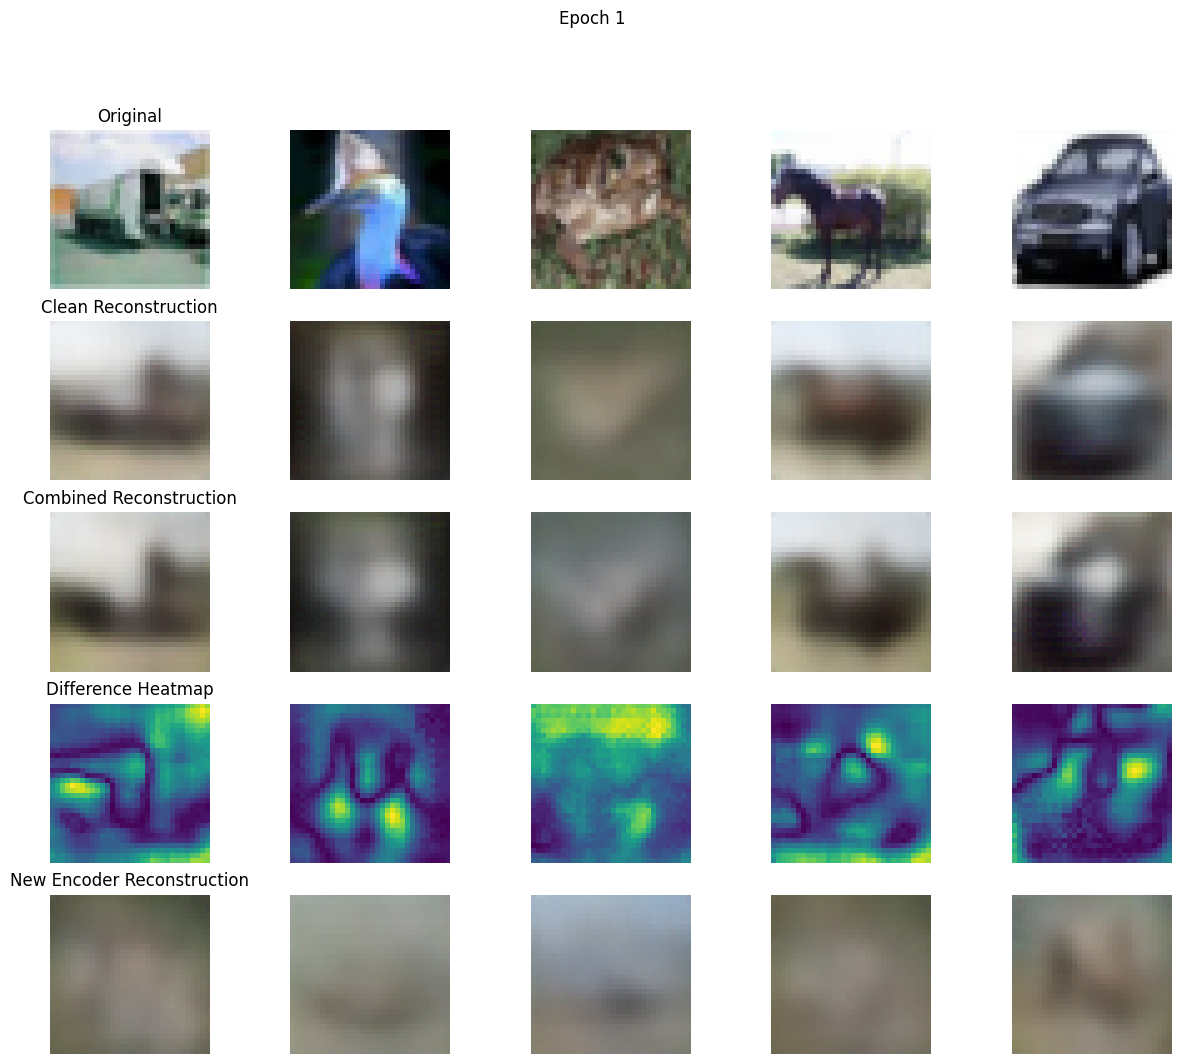

Epoch [2/10], Loss Reconstruction: 0.02674664674884142, Loss CS_Graph: -2.1991003359979984
Test Accuracy: 41.14%


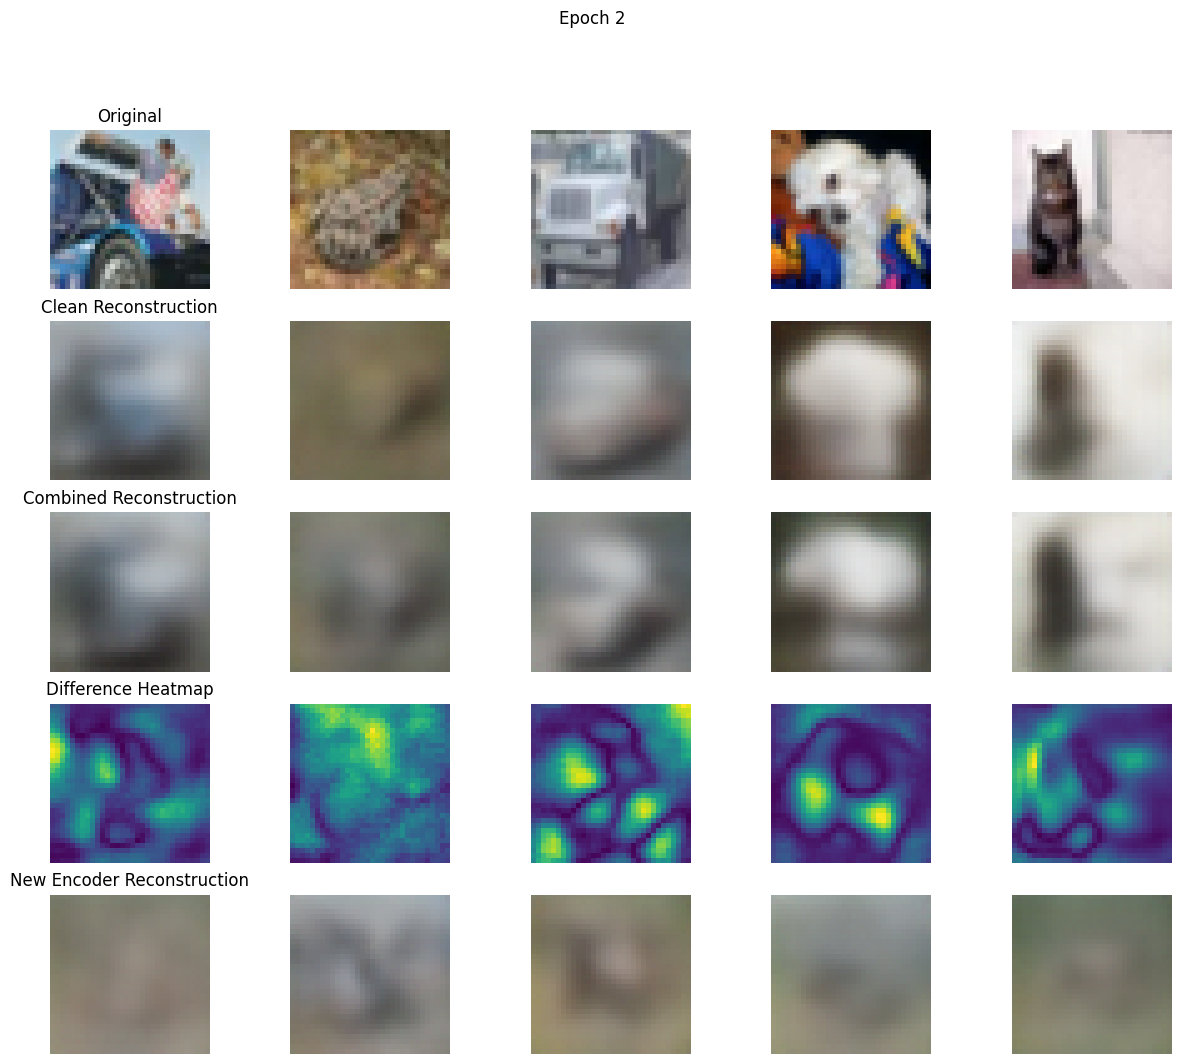

Epoch [3/10], Loss Reconstruction: 0.026844542094832644, Loss CS_Graph: -2.2111456432305943
Test Accuracy: 37.63%


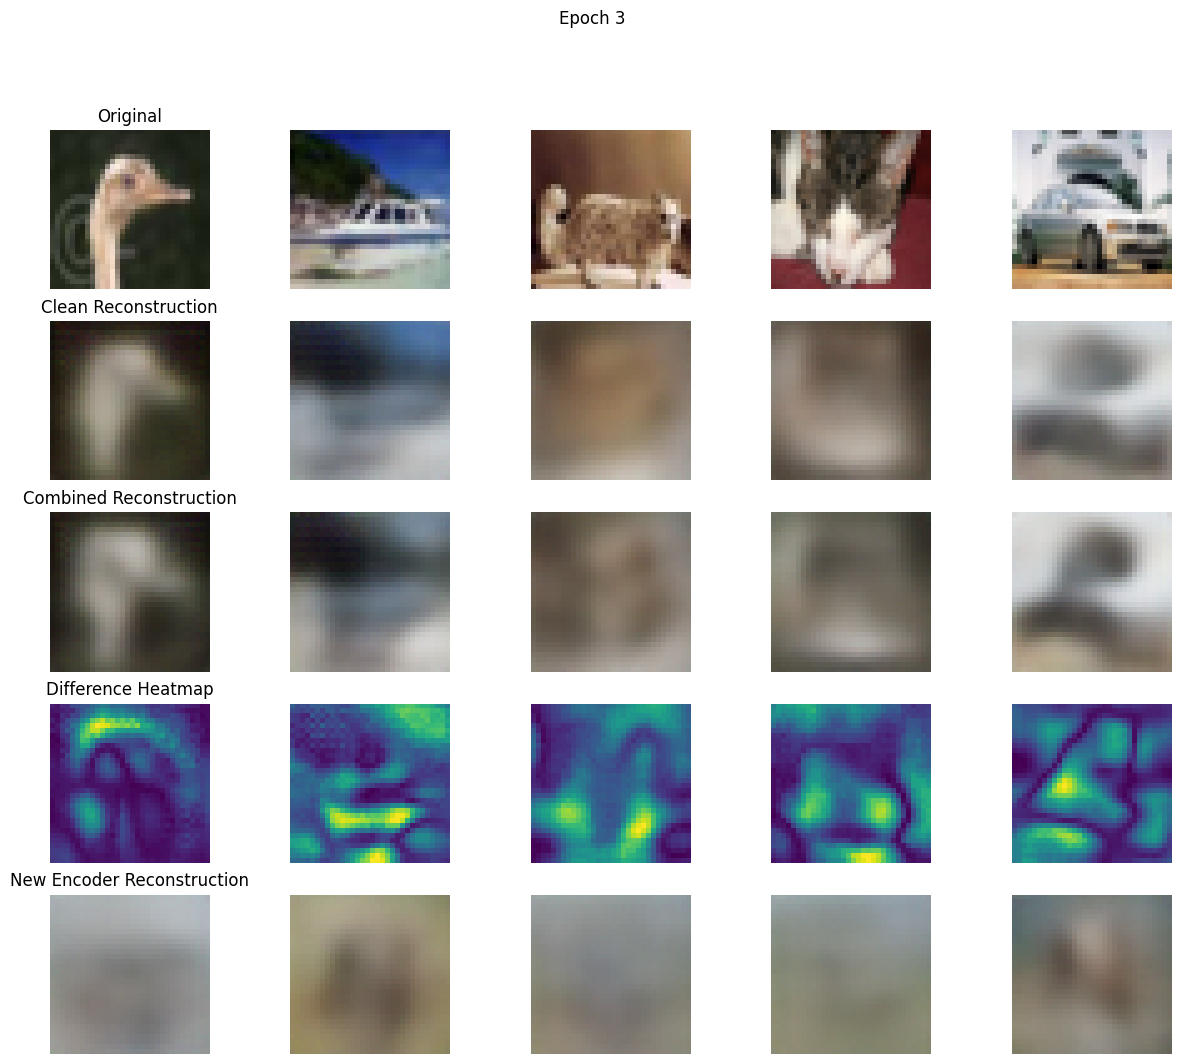

Epoch [4/10], Loss Reconstruction: 0.026902892791173038, Loss CS_Graph: -2.219006877725996
Test Accuracy: 36.31%


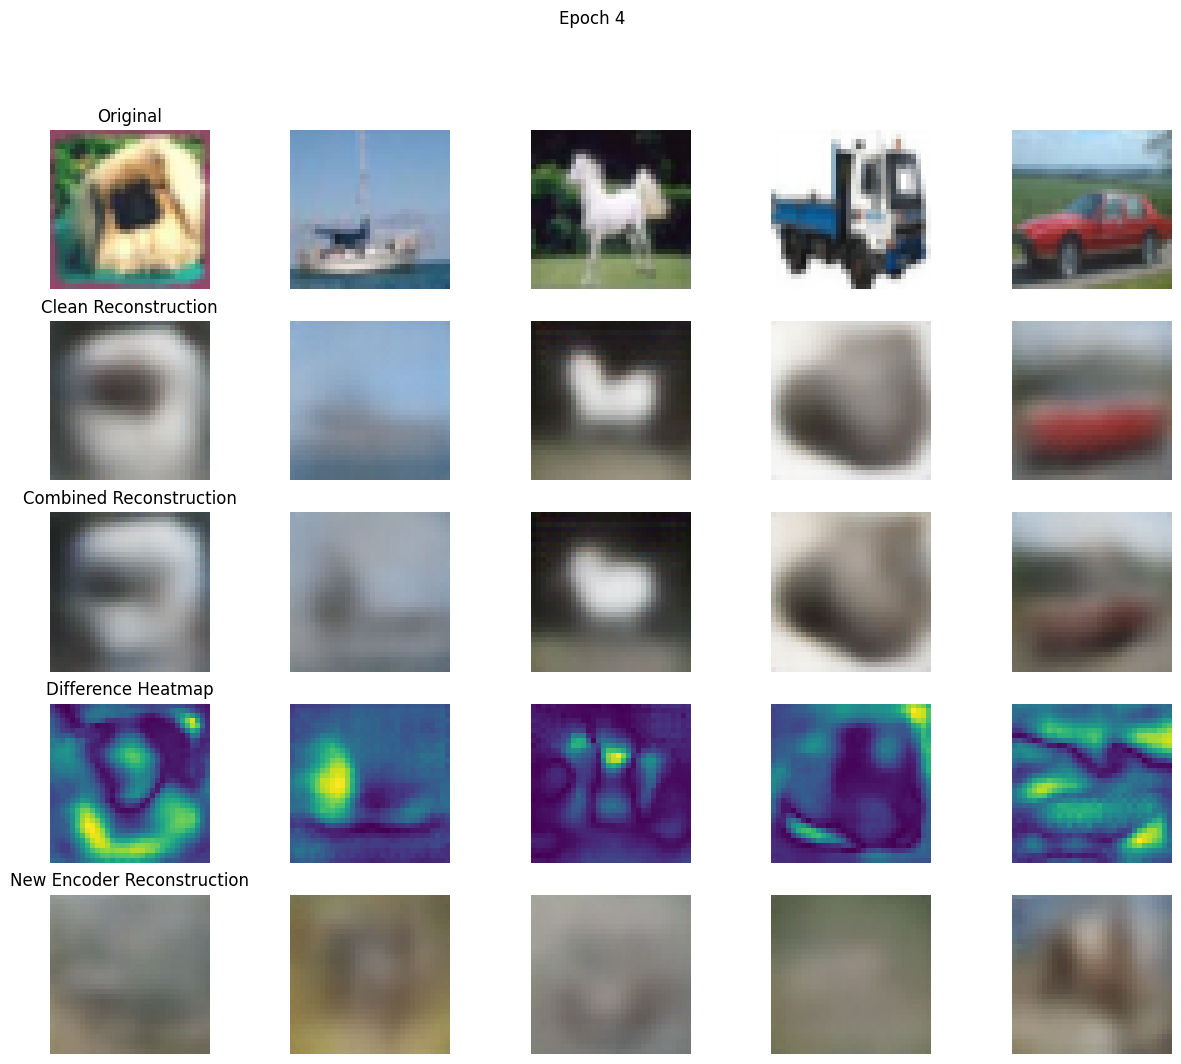

Epoch [5/10], Loss Reconstruction: 0.026940580669437986, Loss CS_Graph: -2.2219619319566983
Test Accuracy: 35.97%


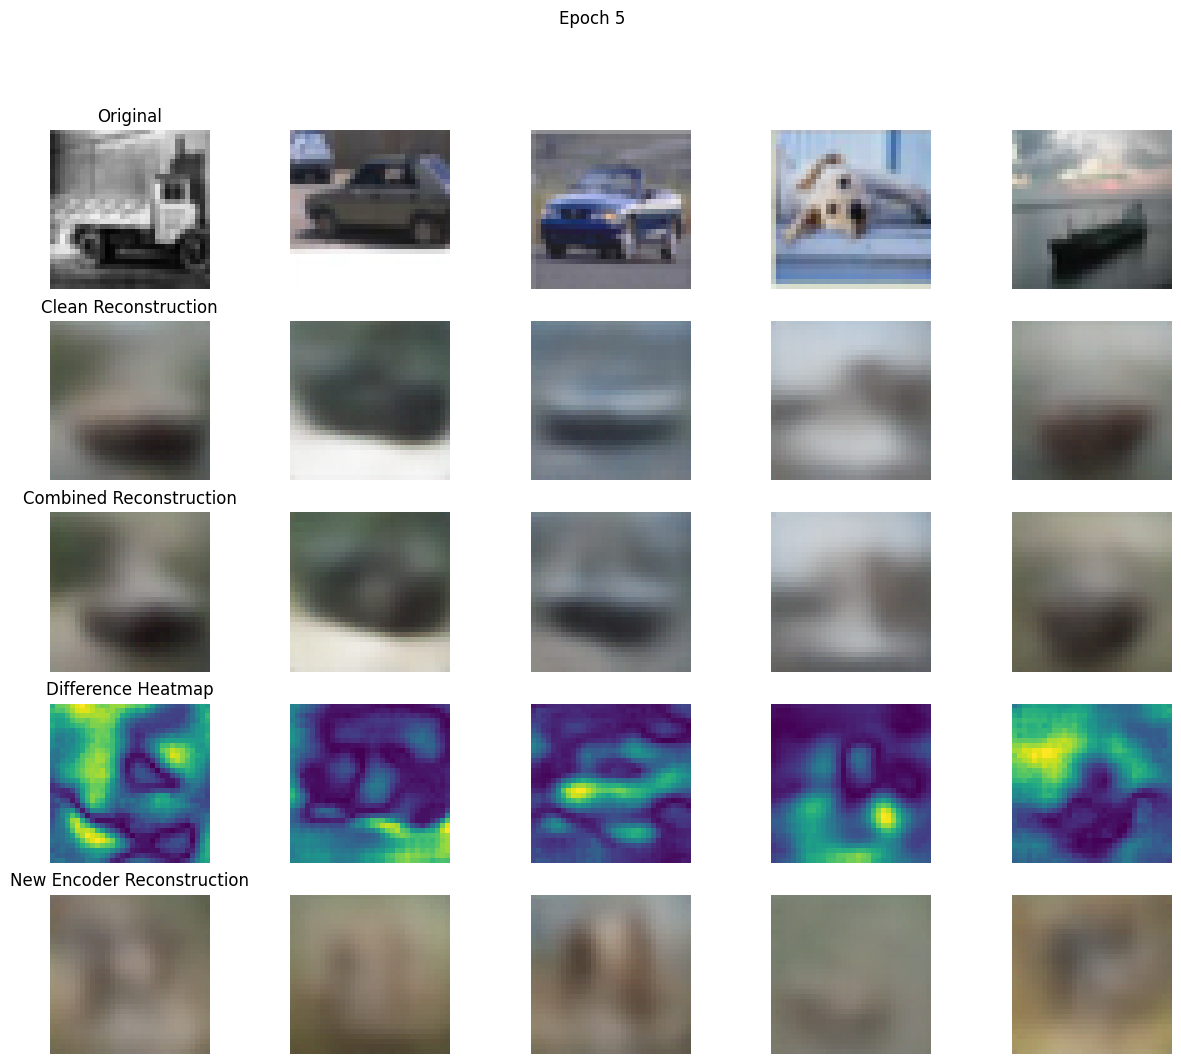

Epoch [6/10], Loss Reconstruction: 0.026962328625990607, Loss CS_Graph: -2.2250272259687827
Test Accuracy: 37.56%


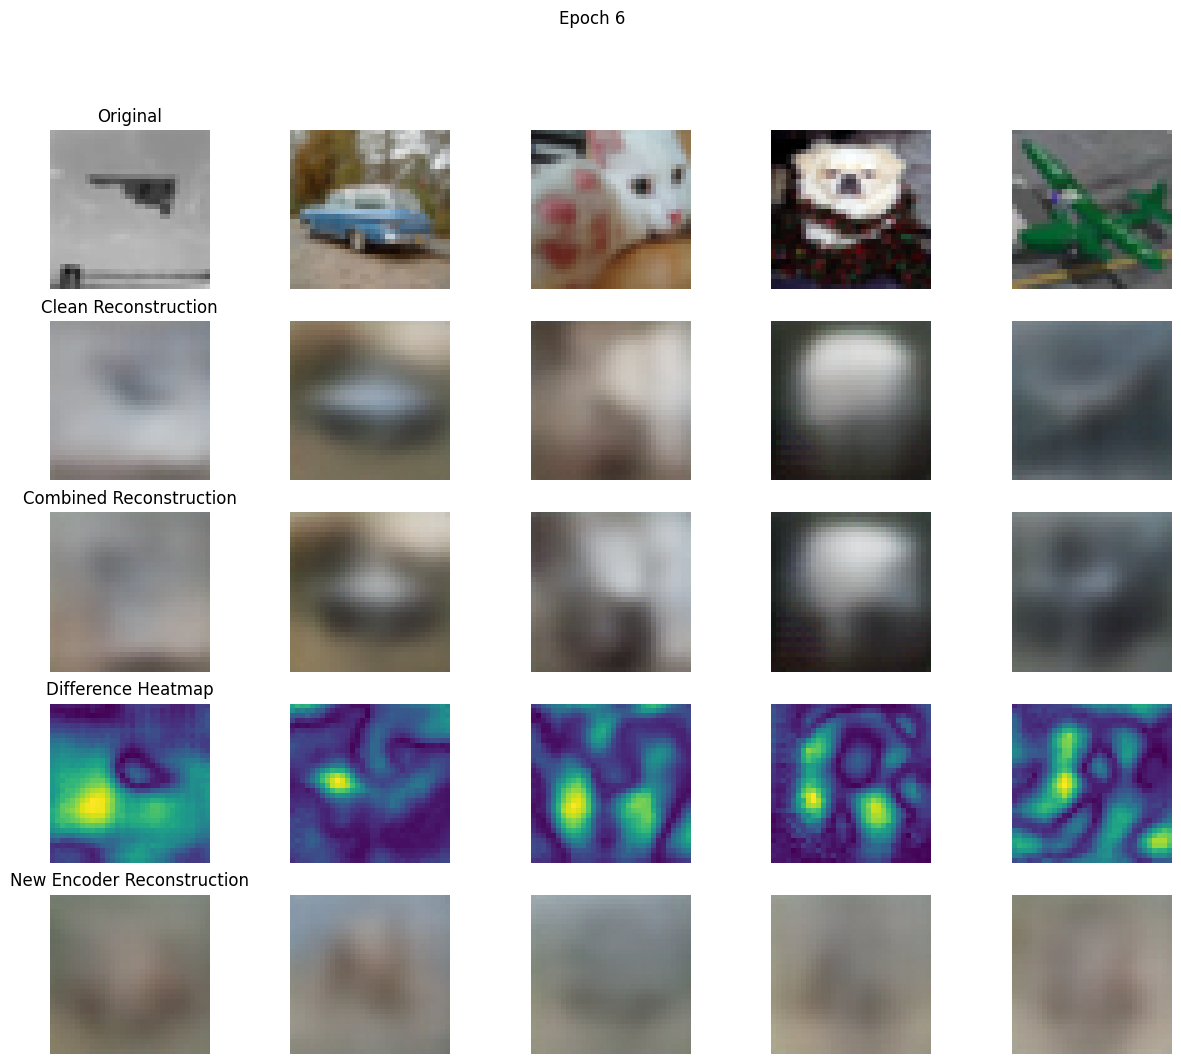

Epoch [7/10], Loss Reconstruction: 0.026959540372442865, Loss CS_Graph: -2.2274997507214853
Test Accuracy: 35.05%


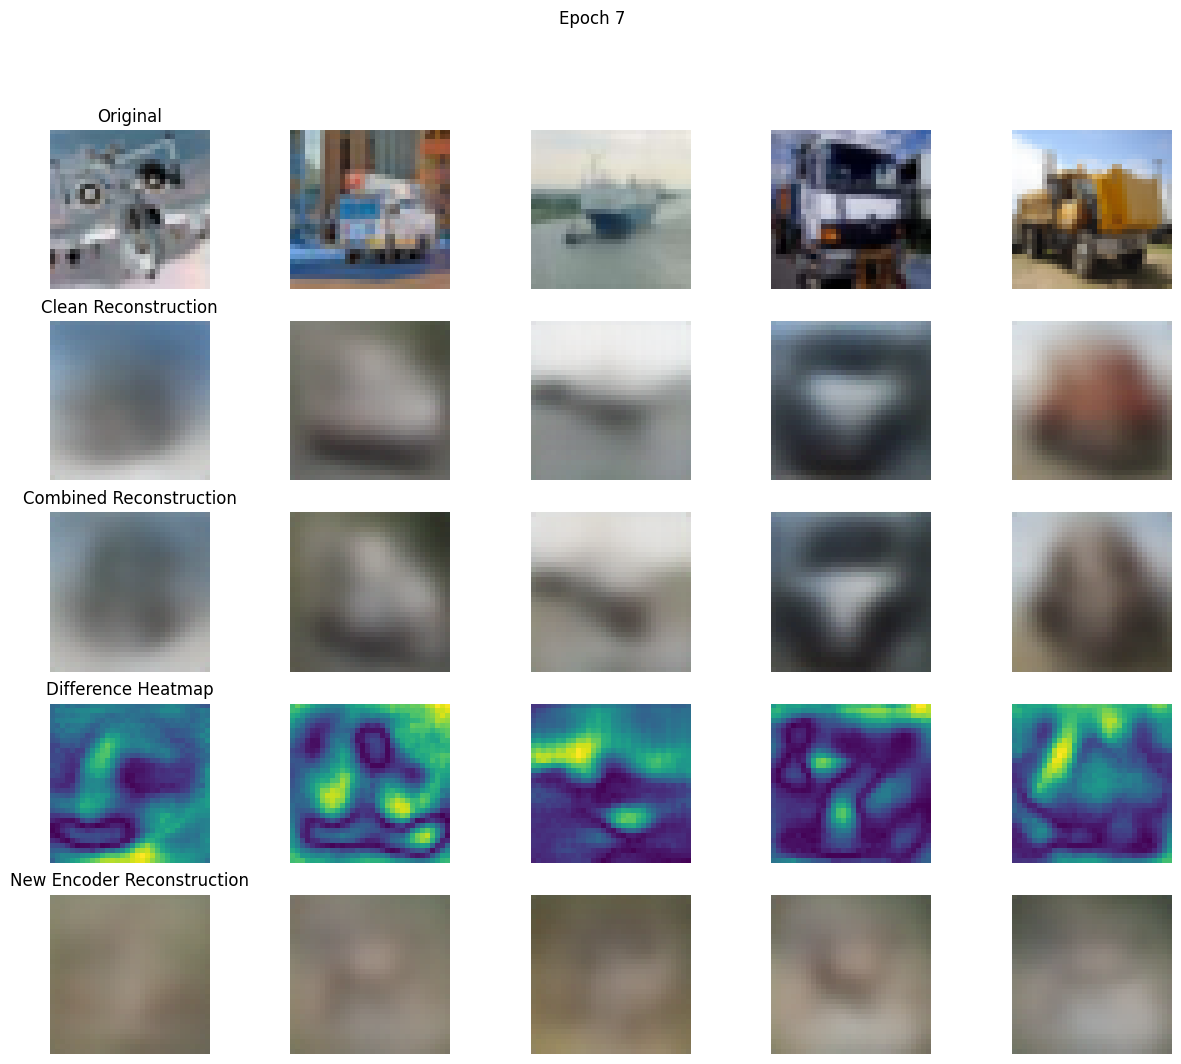

Epoch [8/10], Loss Reconstruction: 0.0269628547184417, Loss CS_Graph: -2.229991745308537
Test Accuracy: 34.8%


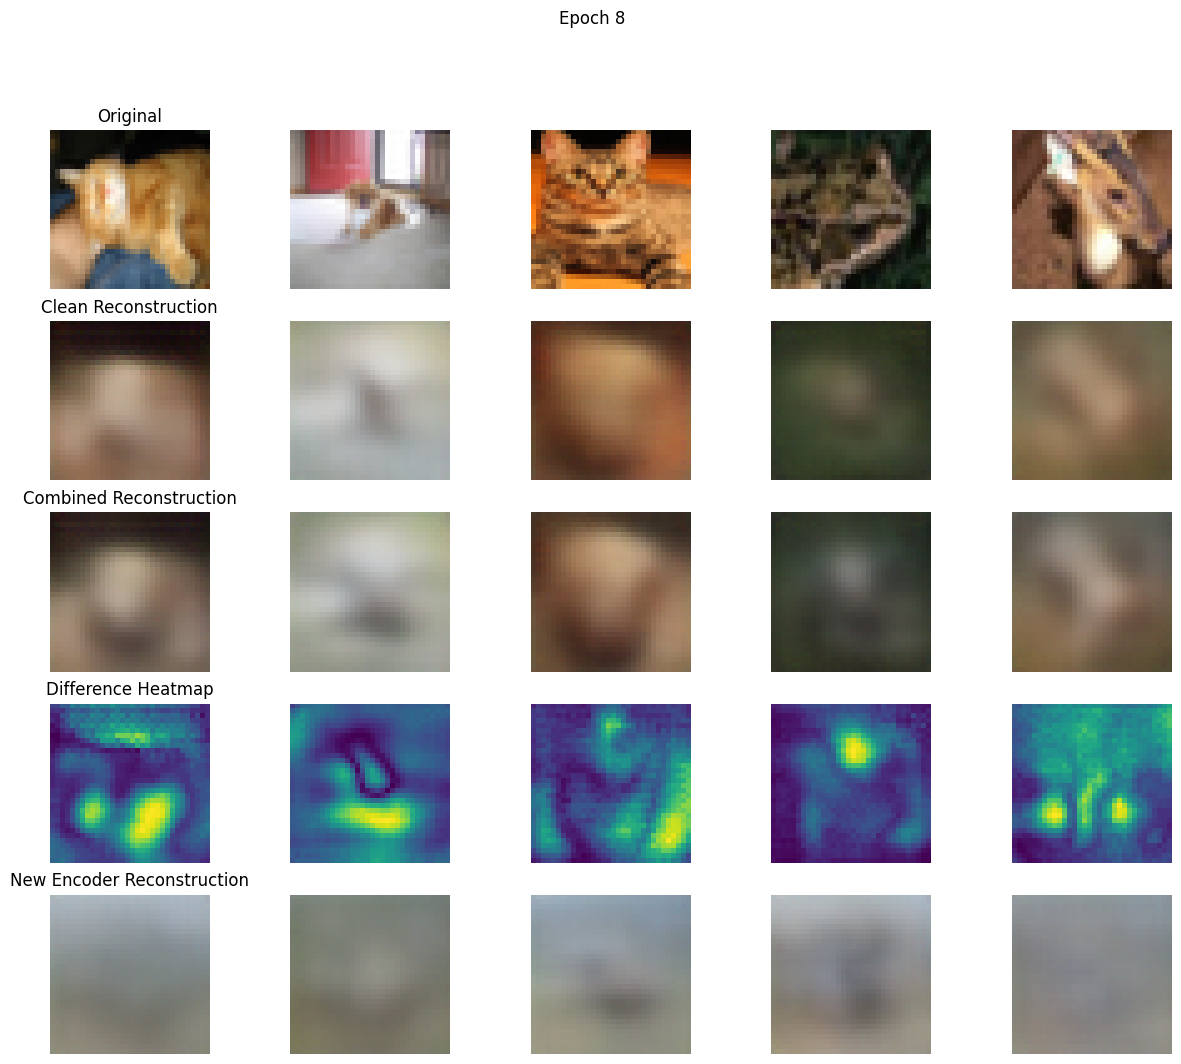

Epoch [9/10], Loss Reconstruction: 0.026962849890332086, Loss CS_Graph: -2.2312548117869344
Test Accuracy: 35.08%


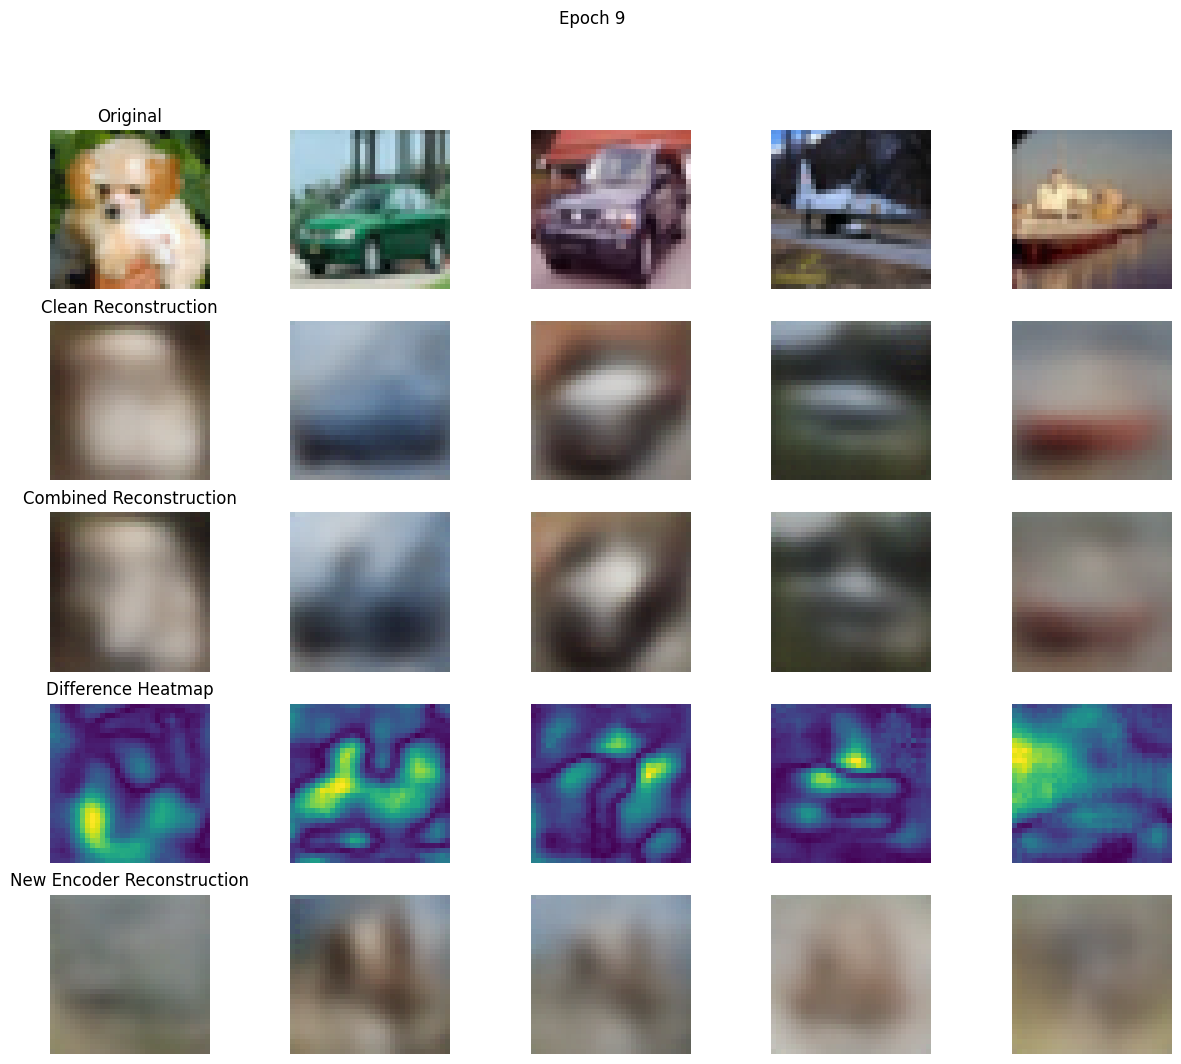

Epoch [10/10], Loss Reconstruction: 0.026943126862482798, Loss CS_Graph: -2.233683792221577
Test Accuracy: 35.19%


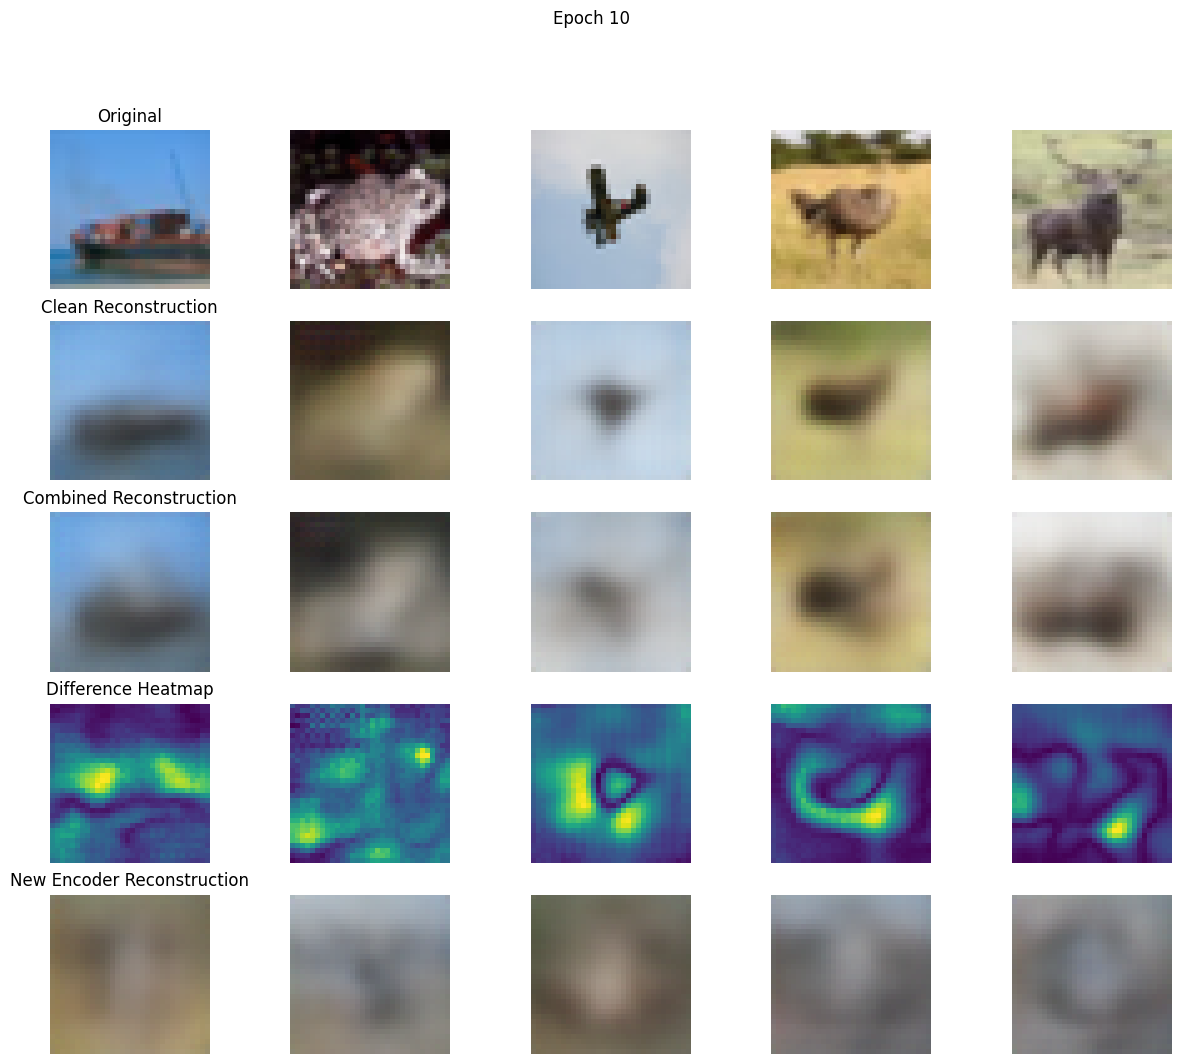

In [19]:
# Assuming LightEncoderWithSigmoid and other necessary classes are defined
new_encoder = LightEncoderWithSigmoid(LightBasicBlockEnc, [2, 2, 2]).to(device)

# To train with supervised method
train_new_encoder(vae, new_encoder, classifier, ae_dataloader, test_dataloader, method='supervised', num_epochs=10) # PTB = 0.75

# To train with CS_Graph method
# train_new_encoder(vae, new_encoder, classifier, ae_dataloader, test_dataloader, method='CS_Graph', num_epochs=10) # PTB = 0.75



---



---



---





---



---



---



---





---



---



---



In [ ]:
# def train_new_encoder(ae, new_encoder, classifier, ae_dataloader, test_dataloader, num_epochs=10, num_classes=10, feature_dim=64):
#     criterion_reconstruction_l2 = nn.MSELoss()
#     criterion_classification = nn.CrossEntropyLoss()
#     criterion_KL = nn.CrossEntropyLoss(reduction='mean')
#     # cross_attention = CrossAttention()
#     pseudo_loss = PseudoLoss()

#     optimizer = optim.Adam(new_encoder.parameters(), lr=0.001)
#     criterion_renyi_entropy = RenyiEntropyLoss(alpha=2.0, sigma=2.0)
#     CS_cross = CS_CrossEntropyLoss(alpha=2.0, sigma=2.0)

#     for epoch in range(num_epochs):
#         new_encoder.train()

#         running_loss_reconstruction = 0.0
#         running_loss_classification = 0.0
#         running_loss_renyi_entropy = 0.0

#         for data in ae_dataloader:
#             inputs, labels = data
#             inputs = inputs.to(device)
#             labels = labels.to(device)

#             optimizer.zero_grad()

#             # Get latent representation and reconstructions from VAE
#             x_recon, mu, logvar = ae(inputs)
#             z = ae.reparameterize(mu, logvar)  # Use VAE's reparameterize function

#             # Use z for both reconstruction and classification
#             encoded_new = new_encoder(inputs)

#             _, encoded_combined = PTB(z, encoded_new)



#             # cross attention
#             # attn_output = cross_attention(z, encoded_new, encoded_new)
#             # encoded_new = encoded_new + attn_output
#             # cross attention

#             # z_norm = torch.norm(z, p=2, dim=1, keepdim=True)

#             # # Normalize encoded_new using max norm
#             # max_vals_new, _ = encoded_new.max(dim=1, keepdim=True)

#             # # Normalize z using max norm
#             # max_vals_z, _ = z.max(dim=1, keepdim=True)

#             # # Calculate scale factor
#             # scale_factor = max_vals_z / max_vals_new * (2 / 255)

#             # # Scale encoded_new
#             # encoded_new_scaled = encoded_new * z_norm

#             # encoded_combined = encoded_new_scaled + z  # Combining new encoder output with VAE's reconstructed output

#             # Reconstruction: combined
#             outputs_reconstruction = ae.decode(encoded_combined)

#             # L2 loss for reconstruction
#             loss_reconstruction_l2 = criterion_reconstruction_l2(outputs_reconstruction, inputs)
#             # Reconstruction loss
#             loss_reconstruction =  loss_reconstruction_l2 # pseudo_loss(z, encoded_combined)

#             # Classification loss: should be maximized
#             outputs_classification = classifier(encoded_combined)
#             loss_classification =  criterion_classification(outputs_classification, labels)

#             renyi_entropy_loss =  0.5 * criterion_renyi_entropy(encoded_combined) + CS_cross(encoded_combined, z) # maximize H(z; z+delta) + 0.5 * H(z+delta)

#             # Total loss: minimize reconstruction loss, maximize classification loss
#             loss = loss_reconstruction  -  loss_classification # renyi_entropy_loss

#             loss.backward()
#             optimizer.step()

#             running_loss_reconstruction += loss_reconstruction.item()
#             running_loss_classification += loss_classification.item()
#             running_loss_renyi_entropy += renyi_entropy_loss.item()


#         print(f'Epoch [{epoch+1}/{num_epochs}], Loss Reconstruction: {running_loss_reconstruction/len(ae_dataloader)}, Loss Classification: {running_loss_classification/len(ae_dataloader)}, Loss Renyi Entropy: {running_loss_renyi_entropy/len(ae_dataloader)}')

#         classifier.eval()
#         correct = 0
#         total = 0
#         with torch.no_grad():
#             for data in test_dataloader:
#                 inputs, labels = data
#                 inputs, labels = inputs.to(device), labels.to(device)
#                 x_recon, mu, logvar = ae(inputs)
#                 z = ae.reparameterize(mu, logvar)
#                 encoded_new = new_encoder(inputs)

#                 _, encoded_combined = PTB(z, encoded_new)

#                 # encoded_combined = encoded_new_scaled + z
#                 outputs = classifier(encoded_combined)
#                 _, predicted = torch.max(outputs.data, 1)
#                 total += labels.size(0)
#                 correct += (predicted == labels).sum().item()

#         print(f'Test Accuracy: {100 * correct / total}%')

#         visualize_new_encoder_outputs(ae, new_encoder, ae_dataloader, epoch)

# # Assuming LightEncoderWithSigmoid and other necessary classes are defined
# new_encoder = LightEncoderWithSigmoid(LightBasicBlockEnc, [2, 2, 2]).to(device)

# train_new_encoder(vae, new_encoder, classifier, ae_dataloader, test_dataloader, num_epochs=5)


In [ ]:
!pip install umap-learn

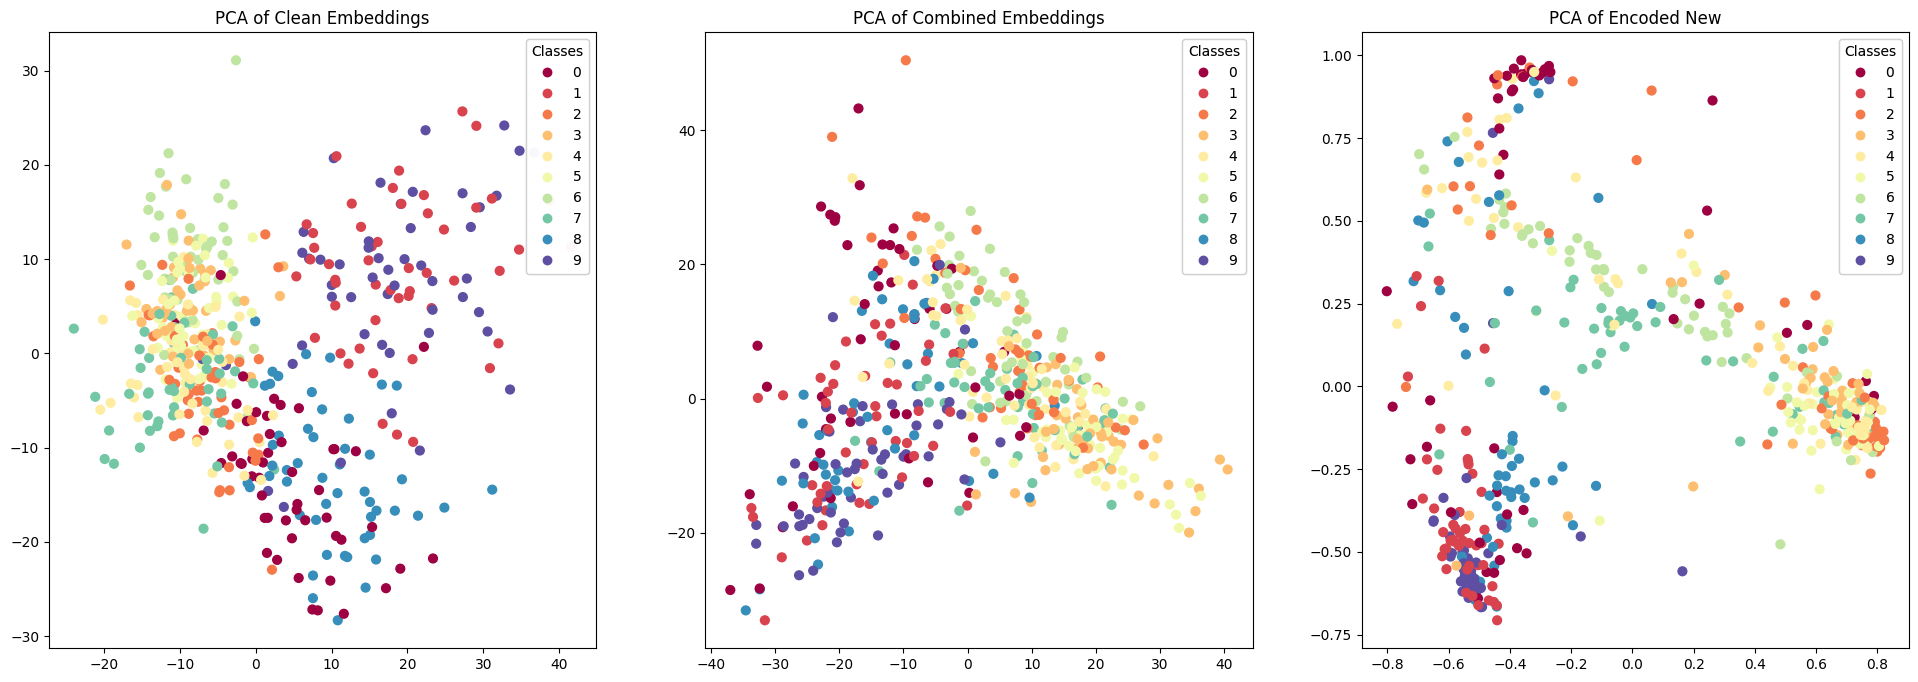

[t-SNE] Computing 121 nearest neighbors...
[t-SNE] Indexed 500 samples in 0.001s...
[t-SNE] Computed neighbors for 500 samples in 0.032s...
[t-SNE] Computed conditional probabilities for sample 500 / 500
[t-SNE] Mean sigma: 9.438197
[t-SNE] KL divergence after 250 iterations with early exaggeration: 57.277138
[t-SNE] KL divergence after 300 iterations: 0.838138
[t-SNE] Computing 121 nearest neighbors...
[t-SNE] Indexed 500 samples in 0.001s...
[t-SNE] Computed neighbors for 500 samples in 0.032s...
[t-SNE] Computed conditional probabilities for sample 500 / 500
[t-SNE] Mean sigma: 9.114060
[t-SNE] KL divergence after 250 iterations with early exaggeration: 55.352081
[t-SNE] KL divergence after 300 iterations: 0.882748
[t-SNE] Computing 121 nearest neighbors...
[t-SNE] Indexed 500 samples in 0.001s...
[t-SNE] Computed neighbors for 500 samples in 0.023s...
[t-SNE] Computed conditional probabilities for sample 500 / 500
[t-SNE] Mean sigma: 0.264323
[t-SNE] KL divergence after 250 iterati

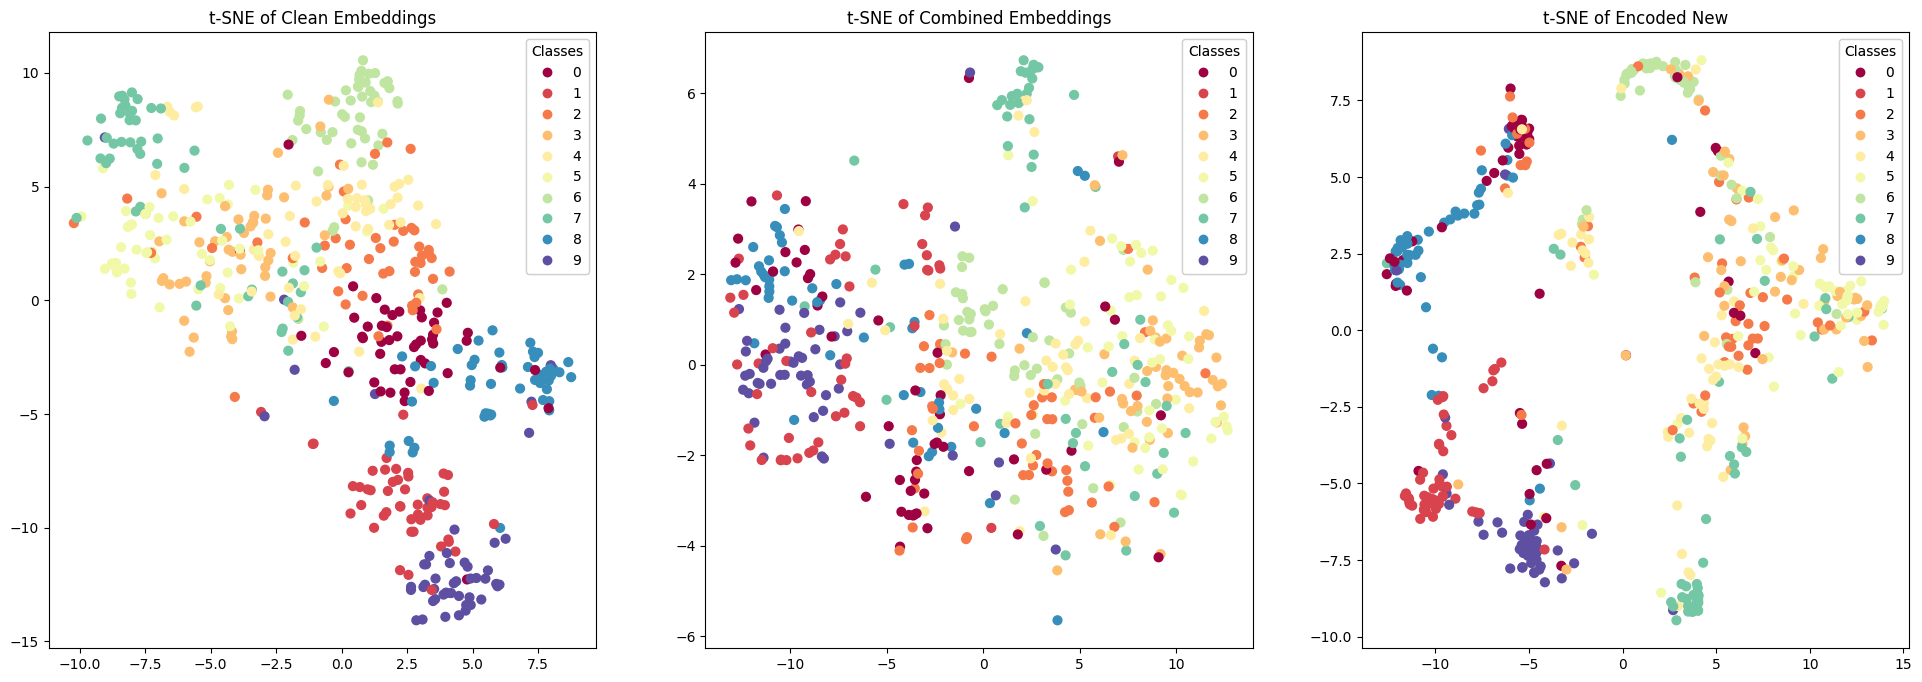

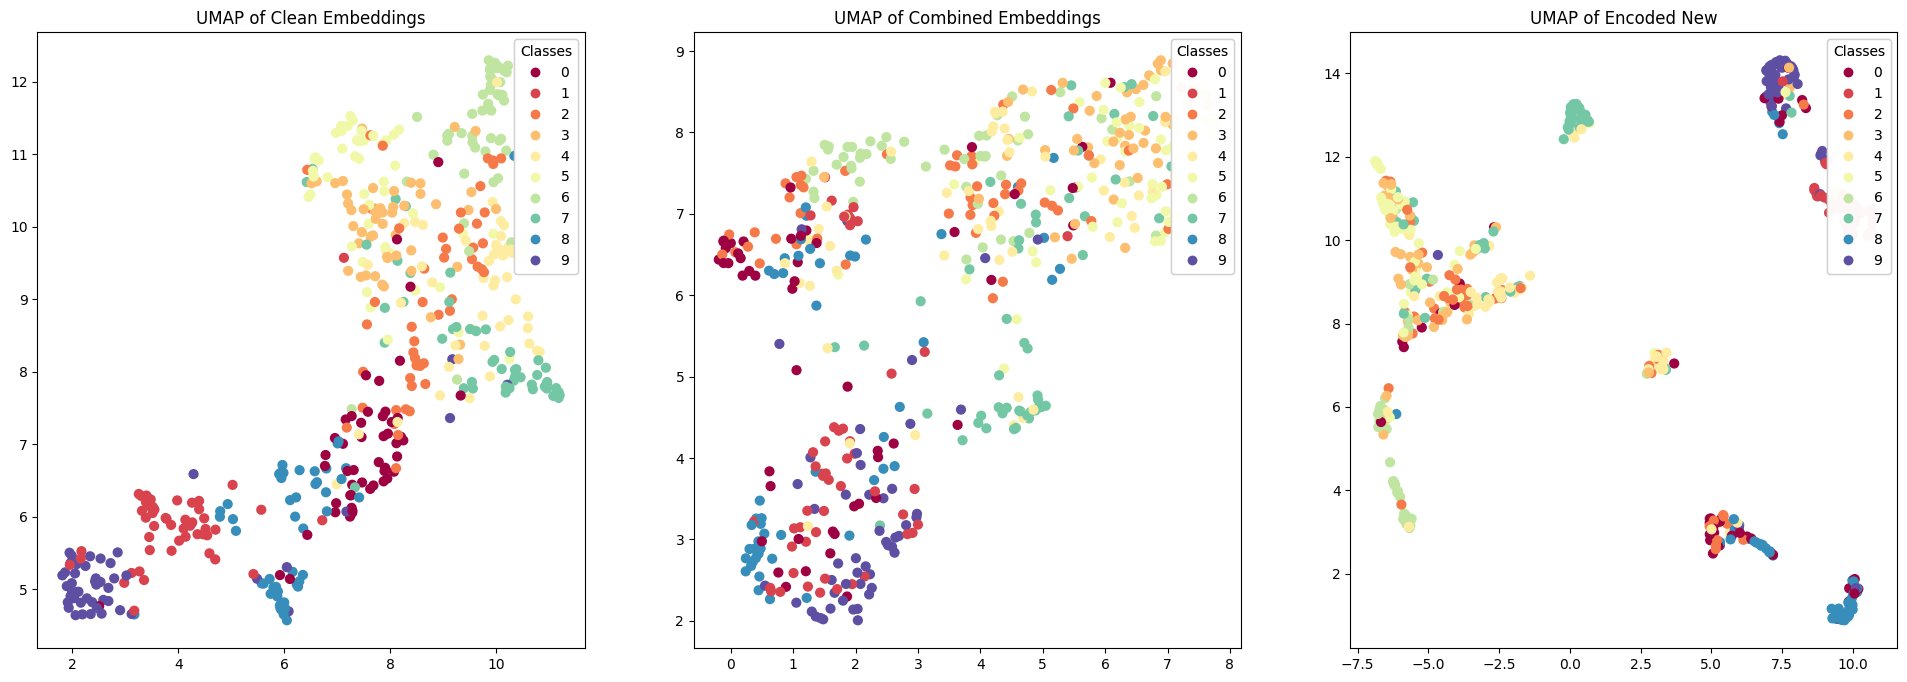

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE
from sklearn.decomposition import PCA
import umap
import torch

def extract_latent_variables(ae, new_encoder, dataloader, num_samples_per_class=50):
    ae.eval()
    new_encoder.eval()
    latent_vars_clean = []
    latent_vars_combined = []
    encoded_news = []
    labels = []

    class_counts = {}
    with torch.no_grad():
        for data in dataloader:
            inputs, targets = data
            inputs = inputs.to(device)
            targets = targets.cpu().numpy()

            _, mu, logvar = ae(inputs)
            z = ae.reparameterize(mu, logvar).cpu().numpy()
            mu = mu.cpu().numpy()

            encoded_new = new_encoder(inputs).cpu().numpy()
            _, encoded_combined = PTB(z, encoded_new)

            # z_norm = np.linalg.norm(z, axis=1, keepdims=True)
            # encoded_combined = z_norm  + z

            for I, label in enumerate(targets):
                if label not in class_counts:
                    class_counts[label] = 0
                if class_counts[label] < num_samples_per_class:
                    latent_vars_clean.append(z[I])
                    latent_vars_combined.append(encoded_combined[I])
                    encoded_news.append(encoded_new[I])
                    labels.append(label)
                    class_counts[label] += 1

    return np.array(latent_vars_clean), np.array(latent_vars_combined), np.array(encoded_news), np.array(labels)

def plot_embeddings(embeddings_clean, embeddings_combined, embeddings_encoded_new, labels, method_name):
    fig, axes = plt.subplots(1, 3, figsize=(24, 8))

    scatter_clean = axes[0].scatter(embeddings_clean[:, 0], embeddings_clean[:, 1], c=labels, cmap='Spectral', s=40)
    legend1 = axes[0].legend(*scatter_clean.legend_elements(), title="Classes", loc="upper right")
    axes[0].add_artist(legend1)
    axes[0].set_title(f"{method_name} of Clean Embeddings")

    scatter_combined = axes[1].scatter(embeddings_combined[:, 0], embeddings_combined[:, 1], c=labels, cmap='Spectral', s=40)
    legend2 = axes[1].legend(*scatter_combined.legend_elements(), title="Classes", loc="upper right")
    axes[1].add_artist(legend2)
    axes[1].set_title(f"{method_name} of Combined Embeddings")

    scatter_encoded_new = axes[2].scatter(embeddings_encoded_new[:, 0], embeddings_encoded_new[:, 1], c=labels, cmap='Spectral', s=40)
    legend3 = axes[2].legend(*scatter_encoded_new.legend_elements(), title="Classes", loc="upper right")
    axes[2].add_artist(legend3)
    axes[2].set_title(f"{method_name} of Encoded New")

    plt.show()

def visualize_latent_space(ae, new_encoder, dataloader, num_samples_per_class=50):
    latent_vars_clean, latent_vars_combined, encoded_news, labels = extract_latent_variables(ae, new_encoder, dataloader, num_samples_per_class)

    # PCA
    pca = PCA(n_components=2)
    pca_clean_result = pca.fit_transform(latent_vars_clean)
    pca_combined_result = pca.fit_transform(latent_vars_combined)
    pca_encoded_new_result = pca.fit_transform(encoded_news)
    plot_embeddings(pca_clean_result, pca_combined_result, pca_encoded_new_result, labels, "PCA")

    # t-SNE
    tsne = TSNE(n_components=2, verbose=1, perplexity=40, n_iter=300)
    tsne_clean_result = tsne.fit_transform(latent_vars_clean)
    tsne_combined_result = tsne.fit_transform(latent_vars_combined)
    tsne_encoded_new_result = tsne.fit_transform(encoded_news)
    plot_embeddings(tsne_clean_result, tsne_combined_result, tsne_encoded_new_result, labels, "t-SNE")

    # UMAP
    umap_model = umap.UMAP(n_components=2)
    umap_clean_result = umap_model.fit_transform(latent_vars_clean)
    umap_combined_result = umap_model.fit_transform(latent_vars_combined)
    umap_encoded_new_result = umap_model.fit_transform(encoded_news)
    plot_embeddings(umap_clean_result, umap_combined_result, umap_encoded_new_result, labels, "UMAP")

# Example usage after training the new encoder
visualize_latent_space(vae, new_encoder, test_dataloader)



---



---



---



----------

**End**




---

